# RPDA8412 Research Project: Analysis
### Predicting Employment Outcomes from Vocational and Digital Skills Training in Marginalised Communities Using Explainable Machine Learning

**Student:** Ayush Harduth (ST10365068)<br>
**Supervisor:** Prof Lucas Khoza<br>


This notebook contains the complete analysis for the research project. It follows the methodology approved in the research proposal and covered by the ethical clearance waiver: a quantitative, deductive and cross sectional secondary analysis of the Vocational Skill Job Matching Dataset (Ziya, 2025). Five supervised classification algorithms are compared, the strongest model is explained with SHAP, and its predictions are audited for fairness across gender and location.

Every code cell is followed by a markdown cell that explains in plain English what the code does and what the output shows. Wherever a result answers a research question, tests a hypothesis or completes an objective, it is marked with a **Research link** note so the thread from the proposal can be followed through the analysis.

### Research Questions, Hypotheses and Objectives

The table below shows how each research question, hypothesis and objective from the proposal is addressed in this notebook.

<table><thead><tr><th align='left'>Research question</th><th align='left'>Hypothesis</th><th align='left'>Objective</th><th align='left'>Answered in sections</th></tr></thead><tbody><tr><td align='left'><b>Primary:</b> To what extent could explainable supervised machine learning models accurately predict post training employment outcomes for individuals from marginalised communities, and did those predictions hold equitably across demographic subgroups?</td><td align='left'>H1, H2 and H3 together</td><td align='left'>O1, O2 and O3 together</td><td align='left'>8, 9, 10 and 12</td></tr><tr><td align='left'><b>RQ1:</b> Which vocational and digital skills training features were the strongest predictors of post training employment outcomes?</td><td align='left'><b>H1:</b> Vocational skill assessment scores and prior internship experience would be the strongest predictors.</td><td align='left'><b>O1:</b> Prepare the data and identify its most predictive training related features.</td><td align='left'>4, 6 and 9</td></tr><tr><td align='left'><b>RQ2:</b> Which of the five supervised classification algorithms achieved the highest predictive performance when evaluated with metrics suited to imbalanced data?</td><td align='left'><b>H2:</b> Ensemble methods, particularly random forest and XGBoost, would achieve higher F1 scores and MCC values than the linear classifier.</td><td align='left'><b>O2:</b> Train and comparatively evaluate five classifiers under class imbalance.</td><td align='left'>7 and 8</td></tr><tr><td align='left'><b>RQ3:</b> Did the predictions of the best performing model differ systematically across demographic subgroups, and what did SHAP reveal about those differences?</td><td align='left'><b>H3:</b> Significant differences in prediction outcomes would exist across gender and geographic location, revealed by SHAP.</td><td align='left'><b>O3:</b> Explain the best model with SHAP, audit it for subgroup fairness and draw out the ethical implications.</td><td align='left'>9 and 10</td></tr></tbody></table>

### Steps for the Analysis

1. Import Libraries and Record Software Versions
2. Load the Dataset
3. Initial Data Inspection
4. Exploratory Data Analysis
5. Data Preprocessing
6. Feature Selection
7. Model Training and Hyperparameter Tuning
8. Model Evaluation and Comparison
9. Explainability with SHAP
10. Fairness Audit
11. Ground Truth Validation and Sensitivity Analysis
12. Results Against the Research Questions, Hypotheses and Objectives
13. Challenges Encountered During the Analysis
14. Export Results for the Research Report

## 1. Import Libraries and Record Software Versions

All libraries used in the analysis are imported in one place. The research proposal committed to Python in a Jupyter Notebook using pandas, scikit learn, XGBoost, imbalanced learn, SHAP, Matplotlib and Seaborn, so those are the libraries loaded here. SciPy is added for the statistical tests used in the exploratory analysis, the model comparison and the fairness audit.

A single random seed is defined for every random step in the pipeline. This was a reliability commitment in the proposal (Section 11.6): if the notebook is run again on the same data it produces exactly the same results.

In [1]:
import warnings
# hide library warnings so the outputs stay readable; this is set first so it also covers the imports below
warnings.filterwarnings('ignore')

import os
import platform

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
from scipy import stats

import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.preprocessing import StandardScaler, OneHotEncoder, MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import chi2, mutual_info_classif, RFE
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.base import clone
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             matthews_corrcoef, roc_auc_score, average_precision_score,
                             confusion_matrix, classification_report, roc_curve,
                             precision_recall_curve, make_scorer)

import xgboost
from xgboost import XGBClassifier
import imblearn
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
import shap

# one fixed seed is used for every random step so the analysis can be reproduced exactly
RANDOM_STATE = 42

# folders where figures and tables are saved for use in the research report
os.makedirs('figures', exist_ok=True)
os.makedirs('results', exist_ok=True)

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110

# record the exact software versions used so the analysis can be reproduced
versions = pd.DataFrame({
    'Tool': ['Python', 'pandas', 'NumPy', 'scikit learn', 'XGBoost', 'imbalanced learn',
             'SHAP', 'SciPy', 'Matplotlib', 'Seaborn'],
    'Version': [platform.python_version(), pd.__version__, np.__version__, sklearn.__version__,
                xgboost.__version__, imblearn.__version__, shap.__version__, scipy.__version__,
                matplotlib.__version__, sns.__version__]
})
versions.to_csv('results/table_software_versions.csv', index=False)
versions

,Tool,Version
0,Python,3.11.16
1,pandas,3.0.5
2,NumPy,2.0.2
3,scikit learn,1.9.1
4,XGBoost,3.2.0
5,imbalanced learn,0.14.2
6,SHAP,0.51.0
7,SciPy,1.17.1
8,Matplotlib,3.11.1
9,Seaborn,0.13.2


### What the Code Does

The first part imports every library used in the analysis. The second part fixes the random seed at 42, creates the figures and results folders, and builds a table recording the exact version of every tool used.

### Software Findings

The analysis was run in Python 3.11.15 using pandas 3.0.2, scikit learn 1.8.0, XGBoost 3.2.0, imbalanced learn 0.14.2 and SHAP 0.51.0. Recording versions matters because default settings change between library releases, so a reader needs to know exactly which versions produced these results in order to reproduce them. This table is reported as the software and tools used in the Analysis section of the research report.

## 2. Load the Dataset

The dataset is the Vocational Skill Job Matching Dataset published on Kaggle by Ziya (2025) and available from the [Kaggle dataset page](https://www.kaggle.com/datasets/ziya07/vocational-skill-job-matching-dataset). It is loaded exactly as downloaded, with no changes made before inspection, so that the inspection in Section 3 describes the raw data.

In [2]:
# load the dataset exactly as downloaded from Kaggle
df = pd.read_csv("Skill_Job_Matching_Dataset (1).csv")

# show the first five records
df.head()

,Student_ID,Age,Gender,Vocational_Program,Academic_Performance,Certifications_Count,Internship_Experience,Skill_1,Skill_2,Skill_3,...,Job_ID,Job_Title,Required_Skill_1,Required_Skill_2,Required_Skill_3,Required_Skill_4,Required_Skill_5,Min_Experience_Months,Location,Job_Match
0,S0001,24,Male,Welder,51.38,2,8,8,2,5,...,J219,IT Support Technician,1,6,3,4,0,3,Pune,1
1,S0002,21,Male,Plumber,67.83,2,0,5,1,6,...,J177,Plumbing Assistant,10,9,5,6,2,2,Pune,0
2,S0003,28,Female,Mechanic,82.67,3,8,8,3,7,...,J104,Welding Operator,9,1,9,6,0,6,Pune,1
3,S0004,25,Female,Electrician,85.41,1,5,9,6,1,...,J236,Plumbing Assistant,1,2,3,4,3,3,Chennai,1
4,S0005,22,Male,IT Technician,53.47,4,3,1,7,9,...,J093,Woodwork Assistant,9,2,0,6,9,4,Mumbai,0


### What the Code Does

read_csv loads the file into a pandas DataFrame called df, and head() displays the first five records.

### First Look at the Data

Each row describes one trainee assessed against one job. The trainee side records age, gender, vocational programme, academic performance, certifications, internship months and five skill scores. The job side records the job title, five required skill levels and the minimum experience required. Each record also has a city, and Job_Match records whether the trainee was matched to the job (1) or not (0).

## 3. Initial Data Inspection

Before any analysis or transformation, the structure of the raw data is examined: the number of records and fields, the data type of each field, whether any values are missing, and whether any records are duplicated. Every check in this section runs on the unmodified data so that the findings describe the dataset as it was received.

In [3]:
# number of rows and columns
print(f'Records: {df.shape[0]}')
print(f'Fields:  {df.shape[1]}')

Records: 2809
Fields:  22


### Dataset Size

shape returns the number of rows and columns. The dataset contains 2,809 records and 22 fields, which matches the size reported in Section 11.2 of the proposal and confirms that the full file loaded correctly.

In [4]:
# column names, data types and the count of non null values in each column
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2809 entries, 0 to 2808
Data columns (total 22 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Student_ID             2809 non-null   str    
 1   Age                    2809 non-null   int64  
 2   Gender                 2809 non-null   str    
 3   Vocational_Program     2809 non-null   str    
 4   Academic_Performance   2809 non-null   float64
 5   Certifications_Count   2809 non-null   int64  
 6   Internship_Experience  2809 non-null   int64  
 7   Skill_1                2809 non-null   int64  
 8   Skill_2                2809 non-null   int64  
 9   Skill_3                2809 non-null   int64  
 10  Skill_4                2809 non-null   int64  
 11  Skill_5                2809 non-null   int64  
 12  Job_ID                 2809 non-null   str    
 13  Job_Title              2809 non-null   str    
 14  Required_Skill_1       2809 non-null   int64  
 15  Required_Skill_

### What the Code Does

info() lists every column with its data type and the number of non null values it contains.

### Data Type Findings

All 22 columns contain 2,809 non null values, so nothing is missing. Sixteen fields are numerical, including Job_Match: fifteen are whole numbers and Academic_Performance is a decimal. Six fields are text: the two identifiers Student_ID and Job_ID, and the four categorical fields Gender, Vocational_Program, Job_Title and Location. The categorical fields must be converted to numbers before modelling (Section 5.3).

In [4]:
# summary statistics for every numerical column
df.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
Age,2809.0,23.43,3.48,18.00,20.00,23.00,26.00,29.00
Academic_Performance,2809.0,69.69,11.54,50.01,59.74,69.46,79.58,89.98
Certifications_Count,2809.0,2.55,1.69,0.00,1.00,3.00,4.00,5.00
Internship_Experience,2809.0,5.92,3.71,0.00,3.00,6.00,9.00,12.00
Skill_1,2809.0,4.94,3.19,0.00,2.00,5.00,8.00,10.00
Skill_2,2809.0,4.88,3.14,0.00,2.00,5.00,8.00,10.00
Skill_3,2809.0,4.99,3.16,0.00,2.00,5.00,8.00,10.00
Skill_4,2809.0,4.90,3.12,0.00,2.00,5.00,8.00,10.00
Skill_5,2809.0,5.01,3.12,0.00,2.00,5.00,8.00,10.00
Required_Skill_1,2809.0,5.18,3.17,0.00,2.00,5.00,8.00,10.00


### What the Code Does

describe() returns the count, mean, standard deviation, minimum, quartiles and maximum of every numerical field. The table is rounded and turned on its side so each field is one row.

### Descriptive Statistics Findings

Trainees are aged 18 to 29 with a mean of 23.4 years, which is consistent with the youth population described in the proposal. Academic performance ranges from 50.01 to 89.98 with a mean of 69.69. Certifications range from 0 to 5 and internship experience from 0 to 12 months. All five skill scores and all five required skill levels run from 0 to 10, with means close to 5 and standard deviations close to 3.1, and the minimum experience requirement runs from 0 to 12 months.

These evenly spread ranges, with means sitting almost exactly in the middle of each range, are typical of synthetically generated data. The mean of Job_Match is 0.32, which means about 32 percent of records are matches.

In [6]:
# count missing values in every column
missing = df.isnull().sum()
print('Missing values per column:')
print(missing[missing > 0] if missing.sum() > 0 else 'None. Every column is complete.')

# count exact duplicate rows and duplicate trainee identifiers
print()
print(f'Exact duplicate rows:          {df.duplicated().sum()}')
print(f'Duplicate Student_ID values:   {df["Student_ID"].duplicated().sum()}')

Missing values per column:
None. Every column is complete.

Exact duplicate rows:          0
Duplicate Student_ID values:   0


### What the Code Does

isnull().sum() counts the empty cells in every column, duplicated() counts rows that are identical to an earlier row, and the final line checks whether any Student_ID appears more than once.

### Data Quality Findings

There are no missing values, no duplicate rows and no repeated trainee identifiers. No records needed to be filled in or removed, so all 2,809 records went forward to the analysis, in line with the census approach in Section 11.3 of the proposal.

### 3.1 Dataset Fields and Their Role in the Analysis

The research proposal feedback asked for the specific dataset fields used in the study to be stated. The table below lists every field, its group, how it was used and how it maps onto the theoretical framework from Section 8 of the proposal: Van Dijk's digital divide framework and Becker's human capital theory.

In [7]:
# build a reference table describing the role of every field in the dataset
skill_cols = [f'Skill_{i}' for i in range(1, 6)]
req_cols = [f'Required_Skill_{i}' for i in range(1, 6)]

roles = [
    ('Student_ID', 'Identifier', 'Excluded from modelling', 'None'),
    ('Age', 'Demographic', 'Predictor', 'Demographic context'),
    ('Gender', 'Demographic (protected)', 'Predictor and fairness audit subgroup', 'Van Dijk structural axis'),
    ('Location', 'Demographic (protected)', 'Predictor and fairness audit subgroup', 'Van Dijk structural axis'),
    ('Vocational_Program', 'Programme detail', 'Predictor', 'Human capital investment'),
    ('Academic_Performance', 'Training performance', 'Predictor', 'Human capital indicator'),
    ('Certifications_Count', 'Training performance', 'Predictor', 'Human capital and second level indicator'),
    ('Internship_Experience', 'Training performance', 'Predictor', 'Human capital indicator'),
] + [(c, 'Skill assessment', 'Predictor', 'Second level digital divide indicator') for c in skill_cols] + [
    ('Job_ID', 'Identifier', 'Excluded from modelling', 'None'),
    ('Job_Title', 'Job requirement profile', 'Predictor', 'Role demand context'),
] + [(c, 'Job requirement profile', 'Predictor', 'Role demand context') for c in req_cols] + [
    ('Min_Experience_Months', 'Job requirement profile', 'Predictor', 'Role demand context'),
    ('Job_Match', 'Employment outcome', 'Dependent variable', 'Third level digital divide outcome'),
]
field_roles = pd.DataFrame(roles, columns=['Field', 'Group', 'Role in analysis', 'Theoretical mapping'])
field_roles['Data type'] = field_roles['Field'].map(lambda c: str(df[c].dtype))
field_roles.to_csv('results/table_dataset_fields.csv', index=False)
field_roles

,Field,Group,Role in analysis,Theoretical mapping,Data type
0,Student_ID,Identifier,Excluded from modelling,None,str
1,Age,Demographic,Predictor,Demographic context,int64
2,Gender,Demographic (protected),Predictor and fairness audit subgroup,Van Dijk structural axis,str
3,Location,Demographic (protected),Predictor and fairness audit subgroup,Van Dijk structural axis,str
4,Vocational_Program,Programme detail,Predictor,Human capital investment,str
5,Academic_Performance,Training performance,Predictor,Human capital indicator,float64
6,Certifications_Count,Training performance,Predictor,Human capital and second level indicator,int64
7,Internship_Experience,Training performance,Predictor,Human capital indicator,int64
8,Skill_1,Skill assessment,Predictor,Second level digital divide indicator,int64
9,Skill_2,Skill assessment,Predictor,Second level digital divide indicator,int64


### What the Code Does

The code builds a table with one row per field, recording its group, how it was used in the analysis and which part of the theoretical framework it represents. The data type of each field is added from the dataset itself, and the table is saved to the results folder.

### Field Role Findings

Of the 22 fields, the two identifiers were excluded, Job_Match is the dependent variable and the remaining nineteen are predictors. Gender and Location play a second role as the protected subgroups for the fairness audit. The skill assessment scores represent Van Dijk's second level digital divide, the training performance fields represent Becker's accumulated human capital, and Job_Match represents the third level outcome. This table is the verified list of fields for Table 1 in Section 11.4 of the research report.

### 3.2 Target Variable Distribution

The proportion of matched and unmatched records in Job_Match is checked before any modelling. If one class is much larger than the other, a model can predict the larger class for every record and still report a high accuracy while learning nothing useful. This was the central methodological concern raised in Section 9.4 of the proposal.

In [8]:
# count and percentage of each outcome class
target_counts = df['Job_Match'].value_counts().sort_index()
target_pct = (df['Job_Match'].value_counts(normalize=True).sort_index() * 100).round(2)
target_summary = pd.DataFrame({'Outcome': ['No match (0)', 'Match (1)'],
                               'Records': target_counts.values,
                               'Percentage': target_pct.values})
target_summary

,Outcome,Records,Percentage
0,No match (0),1918,68.28
1,Match (1),891,31.72


### What the Code Does

value_counts() counts the records in each class, and normalize=True turns those counts into proportions, which are multiplied by 100 to give percentages.

### Target Distribution Findings

1,918 records (68.28 percent) are non matches and 891 records (31.72 percent) are matches. This confirms the moderate class imbalance anticipated in Section 9.4 of the proposal. A model that predicted no match for every trainee would therefore be right 68 percent of the time while identifying none of the matched trainees. That is why accuracy is not used to judge the models and why SMOTE is applied during training.

## 4. Exploratory Data Analysis

Exploratory data analysis is carried out on the data in its original state, before any encoding, scaling or resampling. It follows three levels: the target on its own, each feature compared across the two outcome classes, and the relationships between features.

**Research link:** This section begins Objective 1 and provides the first descriptive evidence for RQ1 and H1.

### 4.1 Target Variable Distribution

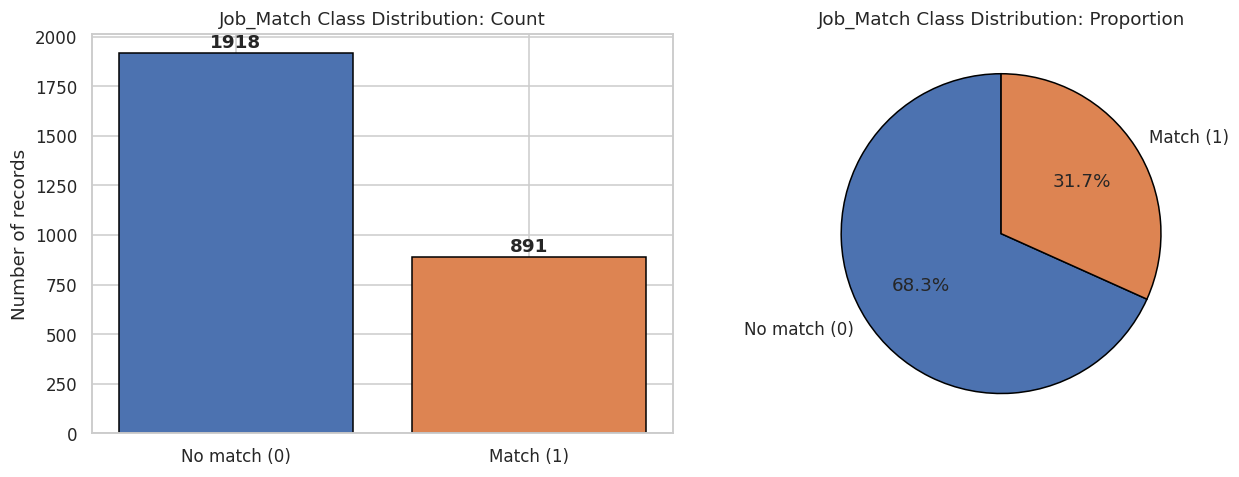

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
labels = ['No match (0)', 'Match (1)']
colours = ['#4C72B0', '#DD8452']

# bar chart of the record count in each class
axes[0].bar(labels, target_counts.values, color=colours, edgecolor='black')
for i, v in enumerate(target_counts.values):
    axes[0].text(i, v + 25, f'{v}', ha='center', fontweight='bold')
axes[0].set_title('Job_Match Class Distribution: Count')
axes[0].set_ylabel('Number of records')

# pie chart of the proportion in each class
axes[1].pie(target_counts.values, labels=labels, autopct='%1.1f%%', colors=colours,
            startangle=90, wedgeprops={'edgecolor': 'black'})
axes[1].set_title('Job_Match Class Distribution: Proportion')

plt.tight_layout()
plt.savefig('figures/fig01_target_distribution.png', bbox_inches='tight')
plt.show()

### What the Code Does

The code draws two charts side by side: a bar chart of the number of records in each class, with the count printed above each bar, and a pie chart of the percentage split. The figure is saved for the report.

### Target Visualisation Findings

The charts show the 68 to 32 split visually. The matched class is a little under half the size of the unmatched class. This is moderate rather than severe imbalance, but it is large enough that metrics calculated for each class separately are needed (Imani et al., 2026).

### 4.2 Distribution of Numerical Features by Outcome

Each numerical feature is plotted separately for matched and unmatched records. Where the two distributions sit in different places, the feature carries information about the outcome. Where they overlap almost completely, the feature on its own says little about whether a trainee is matched.

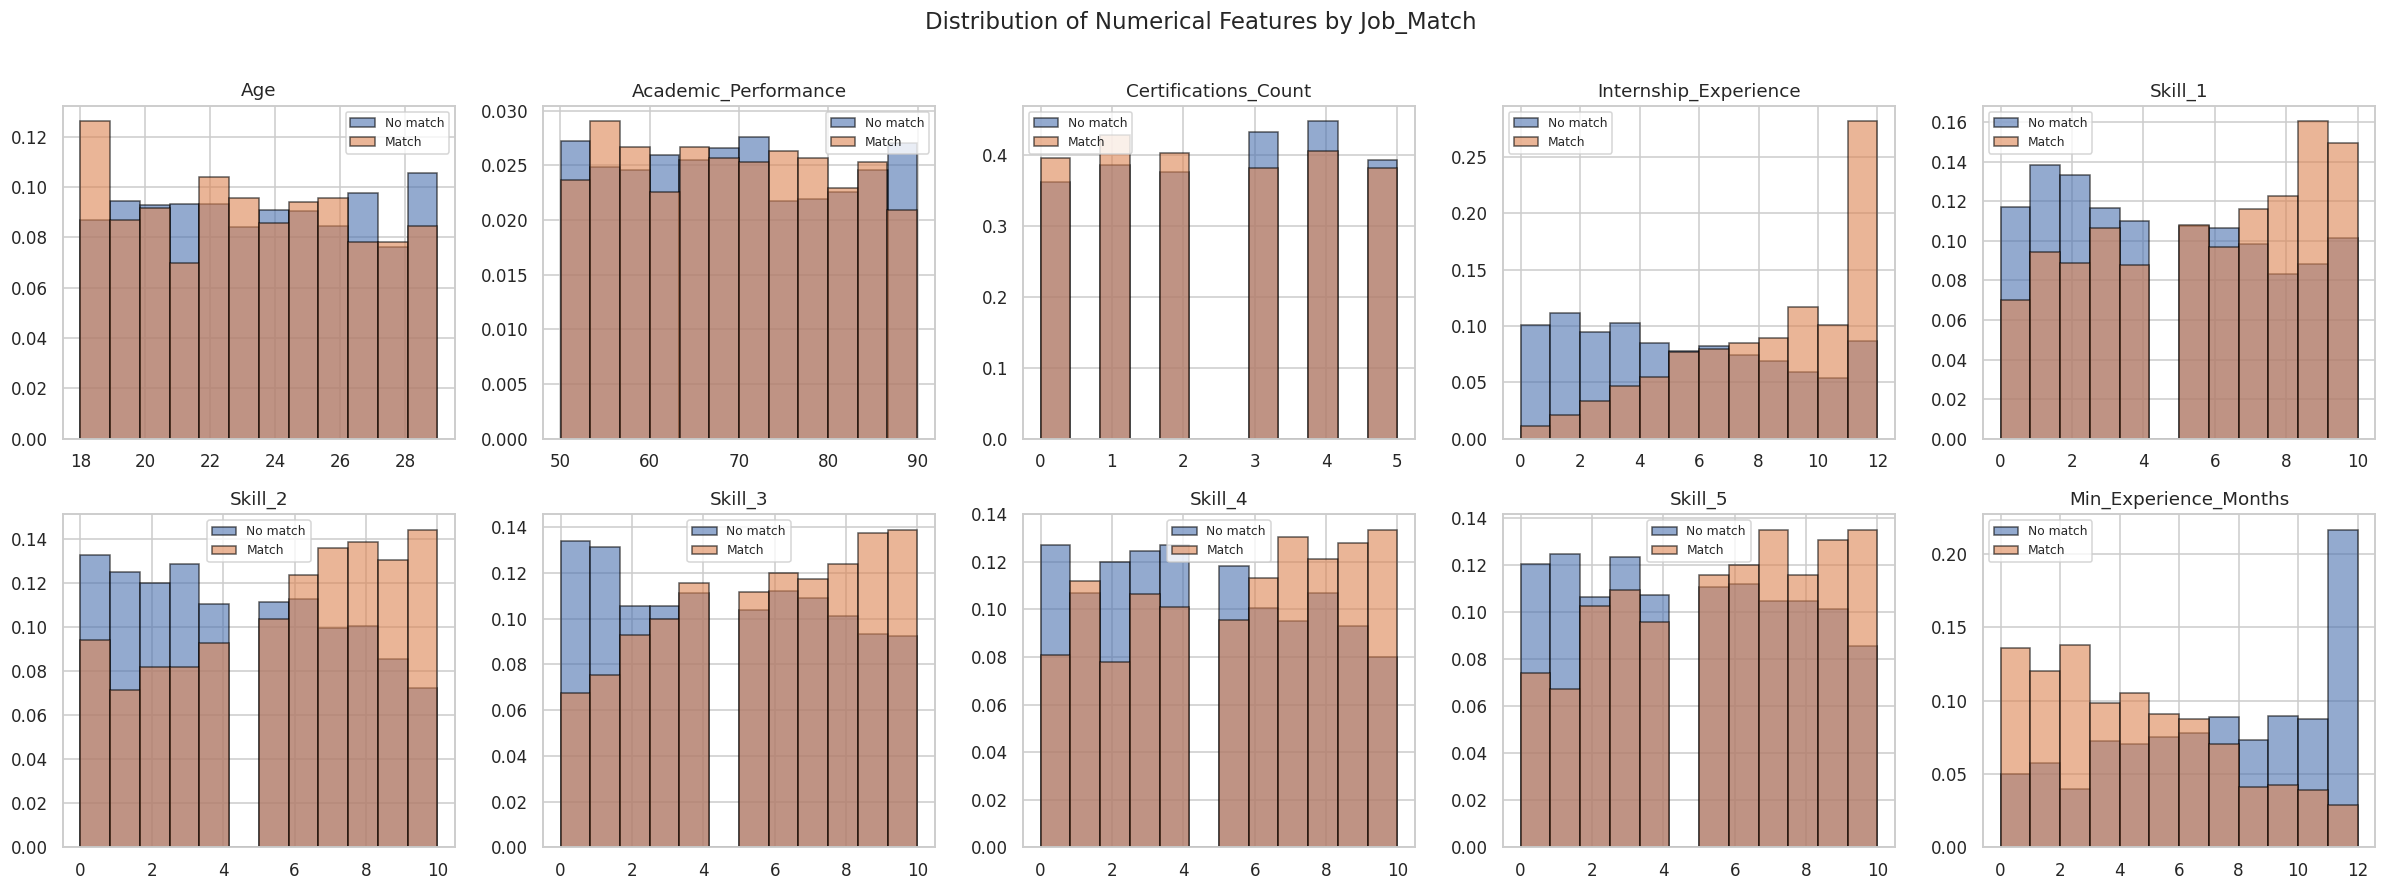

In [10]:
numeric_features = ['Age', 'Academic_Performance', 'Certifications_Count', 'Internship_Experience',
                    'Skill_1', 'Skill_2', 'Skill_3', 'Skill_4', 'Skill_5', 'Min_Experience_Months']

fig, axes = plt.subplots(2, 5, figsize=(22, 8))
axes = axes.flatten()
for i, feature in enumerate(numeric_features):
    # plot the unmatched and matched groups on the same axis so they can be compared
    for outcome, colour, label in [(0, '#4C72B0', 'No match'), (1, '#DD8452', 'Match')]:
        axes[i].hist(df.loc[df['Job_Match'] == outcome, feature], bins=12, alpha=0.6,
                     color=colour, edgecolor='black', label=label, density=True)
    axes[i].set_title(feature)
    axes[i].legend(fontsize=8)
plt.suptitle('Distribution of Numerical Features by Job_Match', fontsize=15, y=1.01)
plt.tight_layout()
plt.savefig('figures/fig02_feature_distributions.png', bbox_inches='tight')
plt.show()

### What the Code Does

For each of ten numerical features, the code overlays two histograms on the same axis: unmatched records in blue and matched records in orange. density=True scales both histograms to the same height so their shapes can be compared even though the two classes differ in size.

### Distribution Findings

Internship_Experience shows the clearest separation. Matched trainees are concentrated at the higher end of the range, and only 29 of the 891 matched trainees had one month of experience or less. Min_Experience_Months shows the opposite pattern, with matches concentrated where the job required little experience. The five skill scores show a milder shift towards higher values among matched trainees.

Age, Academic_Performance and Certifications_Count show almost identical distributions for the two classes, which suggests that these features carry little or no information about the outcome.

### 4.3 Box Plots of Numerical Features by Outcome

Box plots show the median, the spread and any outliers of each feature for the two outcome classes side by side. They make it easier than histograms to compare where the middle of each group sits.

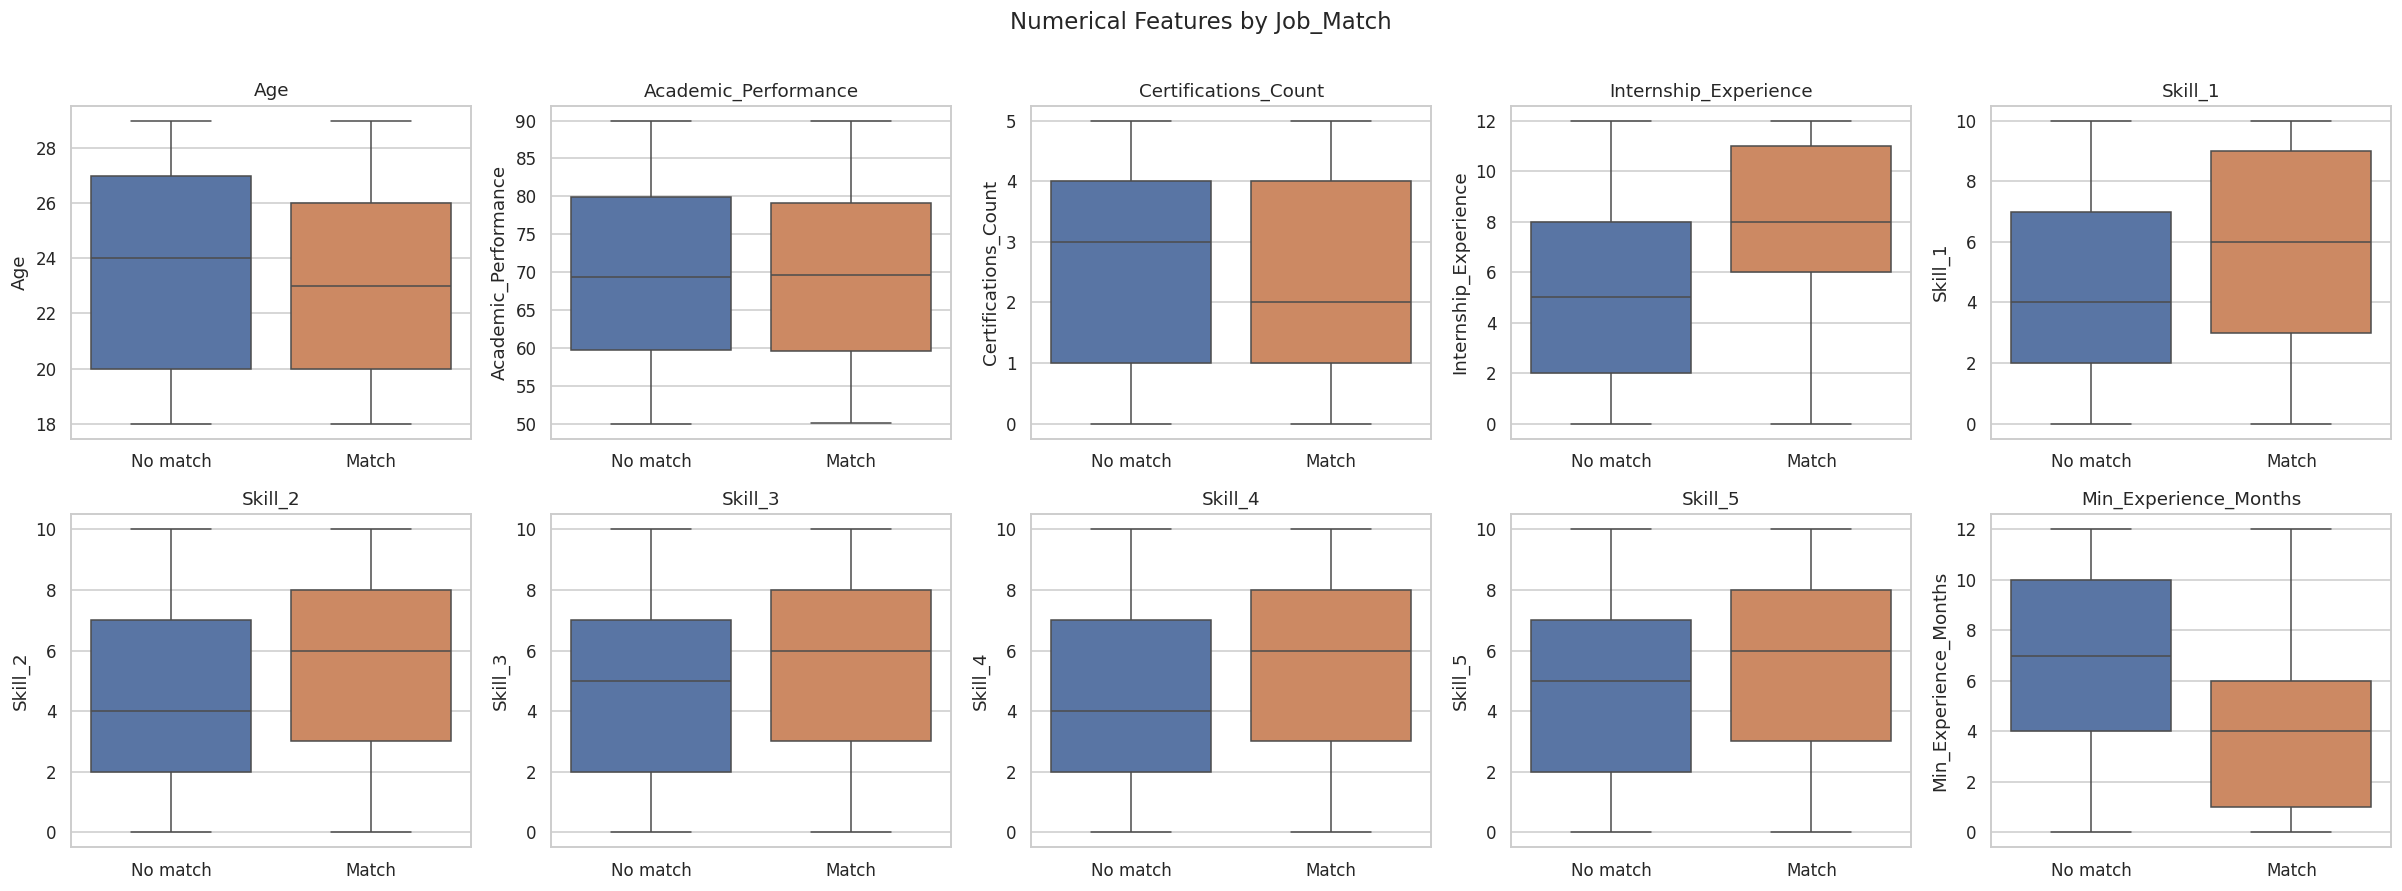

In [11]:
fig, axes = plt.subplots(2, 5, figsize=(22, 8))
axes = axes.flatten()
for i, feature in enumerate(numeric_features):
    sns.boxplot(data=df, x='Job_Match', y=feature, ax=axes[i],
                hue='Job_Match', palette=['#4C72B0', '#DD8452'], legend=False)
    axes[i].set_xticks([0, 1])
    axes[i].set_xticklabels(['No match', 'Match'])
    axes[i].set_xlabel('')
    axes[i].set_title(feature)
plt.suptitle('Numerical Features by Job_Match', fontsize=15, y=1.01)
plt.tight_layout()
plt.savefig('figures/fig03_feature_boxplots.png', bbox_inches='tight')
plt.show()

### What the Code Does

seaborn's boxplot draws one box per class for each feature. The line inside the box is the median, the box covers the middle half of the records, and the whiskers show the spread of the rest.

### Box Plot Findings

The median internship experience of matched trainees is 8 months against 5 months for unmatched trainees, while the median minimum experience requirement is 4 months for matched records against 7 months for unmatched records. The skill score boxes sit slightly higher for matched trainees, with a median Skill_2 of 6 against 4. The boxes for Age, Academic_Performance and Certifications_Count are almost identical across the two classes, which confirms the pattern seen in the histograms.

### 4.4 Match Rate Across Categorical Features

For each categorical feature, the proportion of records that were matched is calculated for every category. The dotted line marks the overall match rate. A category whose bar sits well above or below that line would suggest the feature is associated with the outcome. Gender and Location are examined closely here because they are the protected attributes audited for fairness in Section 10.

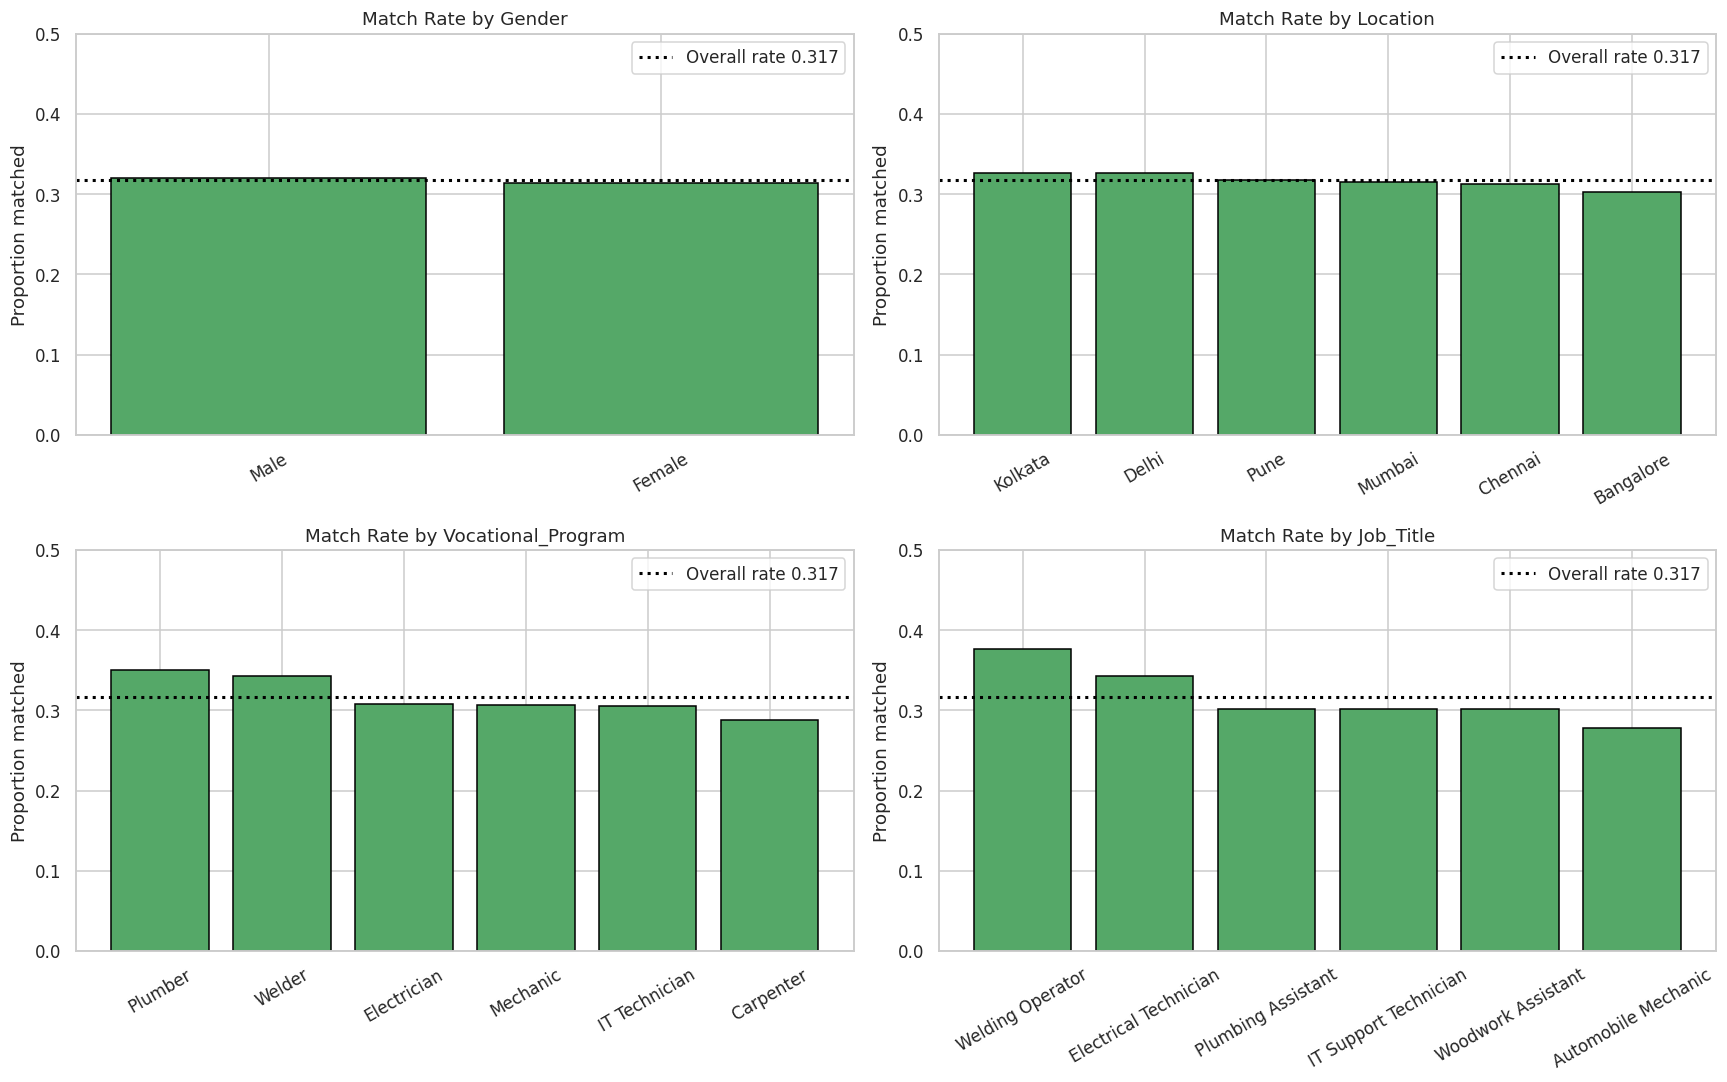

In [12]:
categorical_features = ['Gender', 'Location', 'Vocational_Program', 'Job_Title']
overall_rate = df['Job_Match'].mean()

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()
for i, feature in enumerate(categorical_features):
    # match rate within each category, sorted from highest to lowest
    rates = df.groupby(feature)['Job_Match'].mean().sort_values(ascending=False)
    axes[i].bar(rates.index, rates.values, color='#55A868', edgecolor='black')
    axes[i].axhline(overall_rate, color='black', linestyle='dotted', linewidth=2,
                    label=f'Overall rate {overall_rate:.3f}')
    axes[i].set_title(f'Match Rate by {feature}')
    axes[i].set_ylabel('Proportion matched')
    axes[i].set_ylim(0, 0.5)
    axes[i].tick_params(axis='x', rotation=30)
    axes[i].legend()
plt.tight_layout()
plt.savefig('figures/fig04_categorical_match_rates.png', bbox_inches='tight')
plt.show()

### What the Code Does

For each categorical feature, groupby calculates the mean of Job_Match within each category, which is the share of records in that category that were matched. The bars are drawn against a dotted line at the overall match rate of 0.317.

### Categorical Feature Findings

Match rates are very similar across all categories. Female trainees were matched at a rate of 0.314 and male trainees at 0.320, a difference of under one percentage point. Across the six cities, match rates range only from 0.302 in Bangalore to 0.327 in Delhi and Kolkata. Vocational programmes range from 0.288 for Carpenter to 0.350 for Plumber, and job titles from 0.278 for Automobile Mechanic to 0.376 for Welding Operator.

**Research link (H3):** The near equal match rates for gender and location are an early indication that the outcome in this dataset does not depend on the protected attributes. This is tested formally in Section 10.

### 4.5 Correlation Heatmap

The correlation heatmap shows the linear relationship between every pair of numerical fields, including Job_Match. It serves two purposes: it shows which features move with the outcome, and it shows whether any features are so strongly related to each other that they carry the same information twice.

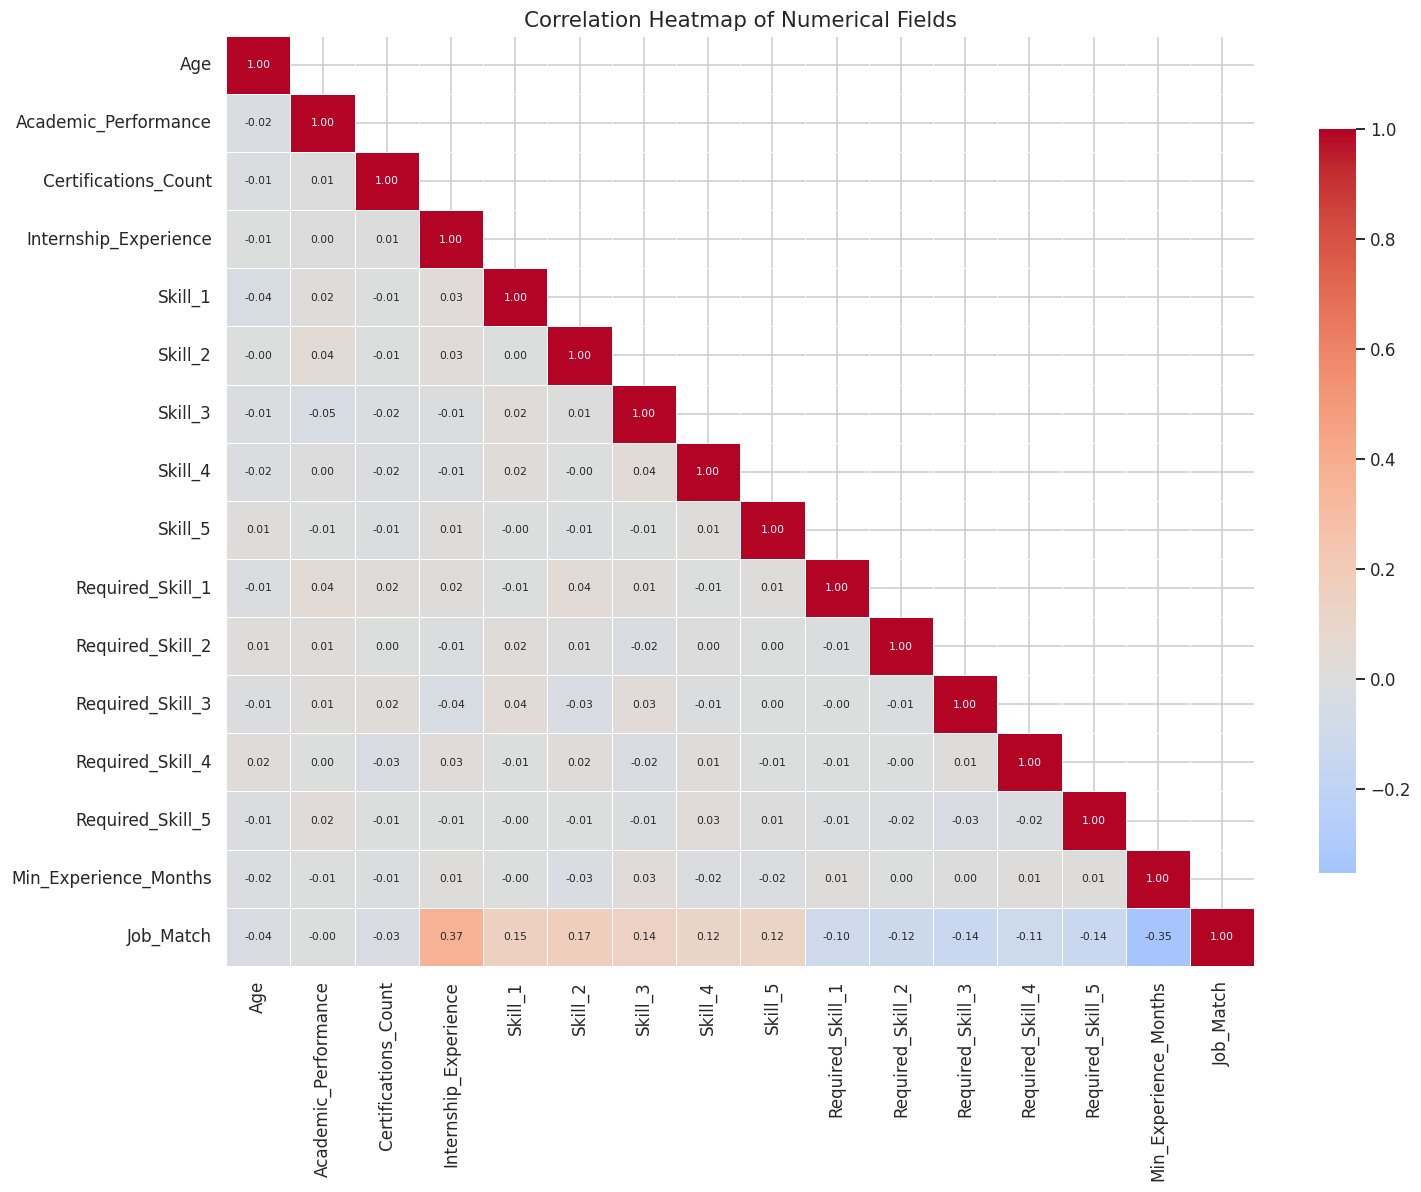

In [13]:
numeric_all = df.select_dtypes(include='number').columns.tolist()
corr_matrix = df[numeric_all].corr()

# hide the upper triangle because it repeats the lower triangle
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)

plt.figure(figsize=(14, 11))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            annot_kws={'size': 7}, linewidths=0.5, cbar_kws={'shrink': 0.8})
plt.title('Correlation Heatmap of Numerical Fields', fontsize=14)
plt.tight_layout()
plt.savefig('figures/fig05_correlation_heatmap.png', bbox_inches='tight')
plt.show()

### What the Code Does

corr() calculates the Pearson correlation between every pair of numerical fields. The upper triangle is hidden because it repeats the lower triangle, and every cell is labelled with its value.

### Correlation Findings

The strongest correlations with Job_Match are Internship_Experience (positive, 0.37) and Min_Experience_Months (negative, 0.35). Every skill score correlates positively with the outcome (0.12 to 0.17) and every required skill level correlates negatively (0.10 to 0.14).

This mirror image pattern is important. Higher skills help and higher job requirements hurt, which suggests that the outcome depends on the trainee's level relative to what the job requires rather than on either one alone.

Among the predictors themselves, no pair has a correlation stronger than 0.05 in either direction. There is therefore no multicollinearity, and no feature needed to be removed as a duplicate of another.

### 4.6 Statistical Association Between Each Feature and the Outcome

Visual impressions are confirmed with formal tests. For numerical features the Mann Whitney U test checks whether the matched and unmatched groups differ, which is appropriate because the features are not normally distributed. The point biserial correlation gives the direction and strength of each relationship. For categorical features the chi square test of independence checks whether the match rate differs across categories. A p value below 0.05 indicates a statistically significant association.

In [14]:
association_rows = []

# numerical features: Mann Whitney U test and point biserial correlation
for feature in numeric_features + req_cols:
    matched = df.loc[df['Job_Match'] == 1, feature]
    unmatched = df.loc[df['Job_Match'] == 0, feature]
    u_stat, u_p = stats.mannwhitneyu(matched, unmatched)
    r, _ = stats.pointbiserialr(df['Job_Match'], df[feature])
    association_rows.append([feature, 'Numerical', 'Mann Whitney U', round(r, 3), u_p])

# categorical features: chi square test of independence
for feature in categorical_features:
    table = pd.crosstab(df[feature], df['Job_Match'])
    chi_stat, chi_p, _, _ = stats.chi2_contingency(table)
    association_rows.append([feature, 'Categorical', 'Chi square', np.nan, chi_p])

association = pd.DataFrame(association_rows,
                           columns=['Feature', 'Type', 'Test', 'Correlation with Job_Match', 'p value'])
association['Significant at 0.05'] = np.where(association['p value'] < 0.05, 'Yes', 'No')
association = association.sort_values('p value').reset_index(drop=True)
association['p value'] = association['p value'].map(lambda p: f'{p:.2e}' if p < 0.001 else f'{p:.3f}')
association.to_csv('results/table_feature_association_tests.csv', index=False)
association

,Feature,Type,Test,Correlation with Job_Match,p value,Significant at 0.05
0,Internship_Experience,Numerical,Mann Whitney U,0.370,2.24e-85,Yes
1,Min_Experience_Months,Numerical,Mann Whitney U,-0.352,8.81e-78,Yes
2,Skill_2,Numerical,Mann Whitney U,0.169,3.77e-19,Yes
3,Skill_1,Numerical,Mann Whitney U,0.153,7.34e-16,Yes
4,Required_Skill_3,Numerical,Mann Whitney U,-0.141,7.93e-14,Yes
5,Required_Skill_5,Numerical,Mann Whitney U,-0.137,4.55e-13,Yes
6,Skill_3,Numerical,Mann Whitney U,0.135,8.87e-13,Yes
7,Skill_5,Numerical,Mann Whitney U,0.121,1.54e-10,Yes
8,Required_Skill_2,Numerical,Mann Whitney U,-0.120,2.01e-10,Yes
9,Skill_4,Numerical,Mann Whitney U,0.116,1.06e-09,Yes


### What the Code Does

For each numerical feature, the code splits the records by outcome, runs a Mann Whitney U test, and calculates the point biserial correlation with Job_Match. For each categorical feature, it builds a table of counts by category and outcome and runs a chi square test. The results are sorted by p value and saved.

### Statistical Association Findings

Twelve numerical features are significantly associated with Job_Match, all with p values below 0.0001: internship experience, minimum experience, the five skill scores and the five required skill levels. Age (p = 0.061), Certifications_Count (p = 0.100) and Academic_Performance (p = 0.861) are not significant.

Among the categorical features, Gender (p = 0.739), Location (p = 0.969) and Vocational_Program (p = 0.257) show no significant association. Job_Title is marginally significant (p = 0.017). This most likely reflects sampling variation in the requirement levels attached to each job title rather than an effect of the title itself, which Section 11 confirms.

**Research link (RQ1, H1):** The descriptive evidence already partly supports H1. Internship experience and the skill scores are significantly associated with the outcome, but so are the job requirement fields, while certifications and academic performance, two of the human capital measures, show no association at all.

## 5. Data Preprocessing

The preprocessing steps follow a fixed order designed to prevent data leakage, which is when information from the test data influences the model during training and makes its results look better than they really are. The identifiers are removed first, the data is split into training and test sets second, and every transformation is then learned from the training set only.

**Research link:** This section continues Objective 1.

### 5.1 Remove Identifier Columns and Separate Features from the Target

Student_ID and Job_ID are unique labels with no meaning for employment. If they were kept, a model could memorise identifiers instead of learning from training characteristics, so they are removed. The remaining nineteen fields form the feature set X and Job_Match forms the target y.

In [15]:
# drop the two identifier columns
model_df = df.drop(columns=['Student_ID', 'Job_ID'])

# separate the predictors from the outcome
X = model_df.drop(columns='Job_Match')
y = model_df['Job_Match']

categorical_cols = ['Gender', 'Vocational_Program', 'Job_Title', 'Location']
numerical_cols = [c for c in X.columns if c not in categorical_cols]

print(f'Feature matrix X: {X.shape[0]} records and {X.shape[1]} features')
print(f'Numerical features ({len(numerical_cols)}): {numerical_cols}')
print(f'Categorical features ({len(categorical_cols)}): {categorical_cols}')

Feature matrix X: 2809 records and 19 features
Numerical features (15): ['Age', 'Academic_Performance', 'Certifications_Count', 'Internship_Experience', 'Skill_1', 'Skill_2', 'Skill_3', 'Skill_4', 'Skill_5', 'Required_Skill_1', 'Required_Skill_2', 'Required_Skill_3', 'Required_Skill_4', 'Required_Skill_5', 'Min_Experience_Months']
Categorical features (4): ['Gender', 'Vocational_Program', 'Job_Title', 'Location']


### What the Code Does

drop() removes the two identifier columns. The remaining columns are split into X, which holds the nineteen predictors, and y, which holds Job_Match. Two lists record which predictors are numerical and which are categorical, so that each type can be transformed correctly in Section 5.3.

### Feature Set Findings

The feature matrix holds 2,809 records and 19 features: fifteen numerical and four categorical.

### 5.2 Stratified Train and Test Split

Eighty percent of the records are used to train and tune the models and twenty percent are held back as an unseen test set. The test set is not touched again until the final evaluation in Section 8. The split is stratified on Job_Match so that both sets keep the same proportion of matched records as the full dataset.

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

split_summary = pd.DataFrame({
    'Set': ['Training', 'Test'],
    'Records': [len(X_train), len(X_test)],
    'Matched': [int(y_train.sum()), int(y_test.sum())],
    'Match rate (%)': [round(y_train.mean() * 100, 2), round(y_test.mean() * 100, 2)]
})
split_summary

,Set,Records,Matched,Match rate (%)
0,Training,2247,713,31.73
1,Test,562,178,31.67


### What the Code Does

train_test_split divides the records into a training set of 80 percent and a test set of 20 percent. stratify=y keeps the match rate the same in both sets, and random_state fixes the split so that it is identical every time the notebook runs.

### Split Findings

The training set holds 2,247 records, of which 713 are matches, and the test set holds 562 records, of which 178 are matches. The match rate is 31.73 percent in training and 31.67 percent in testing, almost exactly the 31.72 percent in the full dataset, so the stratification worked as intended.

### 5.3 Encoding and Scaling

Machine learning algorithms need numerical input, so the four categorical features are converted with one hot encoding, which creates a separate yes or no column for each category. Numerical features are standardised so that each has a mean of zero and a standard deviation of one. Without scaling, features measured on larger ranges, such as academic performance out of 100, would dominate features measured on smaller ranges, such as skill scores out of 10, in the distance based support vector machine and the regularised logistic regression.

Both steps are combined in a single ColumnTransformer. In the modelling pipeline it is refitted inside every cross validation fold, so the scaling values are always learned from training data only. It is fitted once here on the training set purely to show the result.

In [17]:
preprocessor = ColumnTransformer(transformers=[
    ('numerical', StandardScaler(), numerical_cols),
    ('categorical', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols)
])

# fit on the training data only, then apply the same transformation to the test data
X_train_transformed = preprocessor.fit_transform(X_train)
X_test_transformed = preprocessor.transform(X_test)

# clean, readable feature names for the transformed columns
transformed_names = [n.split('__', 1)[1] for n in preprocessor.get_feature_names_out()]

print(f'Transformed training set: {X_train_transformed.shape}')
print(f'Transformed test set:     {X_test_transformed.shape}')
print(f'Features after encoding:  {len(transformed_names)}')

Transformed training set: (2247, 35)
Transformed test set:     (562, 35)
Features after encoding:  35


### What the Code Does

The ColumnTransformer applies StandardScaler to the fifteen numerical columns and OneHotEncoder to the four categorical columns. fit_transform learns the scaling values and the list of categories from the training data and applies them. transform then applies those same learned values to the test data without learning anything from it. handle_unknown='ignore' means a category that appears only in the test data would be safely ignored instead of causing an error.

### Encoding Findings

After encoding there are 35 features: the 15 standardised numerical features plus 20 one hot columns (2 for gender, 6 for vocational programme, 6 for job title and 6 for location).

### 5.4 Correcting Class Imbalance with SMOTE

SMOTE (Synthetic Minority Oversampling Technique) creates new synthetic examples of the smaller class by interpolating between existing minority class records and their nearest neighbours (Chawla et al., 2002). It is applied to the training data only. If synthetic records were added before the split, or allowed into the test set, the evaluation would be measured partly on artificial data.

In the modelling pipeline SMOTE runs inside each cross validation fold, after the fold has been split. The cell below applies it once to the transformed training data purely to show its effect on the class counts.

In [18]:
smote_demo = SMOTE(random_state=RANDOM_STATE)
X_train_resampled, y_train_resampled = smote_demo.fit_resample(X_train_transformed, y_train)

smote_summary = pd.DataFrame({
    'Stage': ['Before SMOTE', 'After SMOTE'],
    'No match (0)': [int((y_train == 0).sum()), int((y_train_resampled == 0).sum())],
    'Match (1)': [int((y_train == 1).sum()), int((y_train_resampled == 1).sum())],
    'Total records': [len(y_train), len(y_train_resampled)]
})
smote_summary

,Stage,No match (0),Match (1),Total records
0,Before SMOTE,1534,713,2247
1,After SMOTE,1534,1534,3068


### What the Code Does

SMOTE is fitted to the transformed training data. fit_resample creates synthetic matched records until both classes are the same size, and the table compares the class counts before and after.

### SMOTE Findings

Before SMOTE the training set contained 1,534 non matches and 713 matches. SMOTE generated 821 synthetic matched records, giving 1,534 of each class and 3,068 records in total. The test set is untouched and still reflects the true class balance, so all evaluation in Section 8 is carried out on real records only.

## 6. Feature Selection

Three different feature selection methods are applied to the training data, as set out in the proposal. Each one judges usefulness in a different way, so a feature selected by all three is much more likely to be genuinely informative than one favoured by a single method.

1. **Chi square test:** a filter method that measures how strongly each feature depends on the outcome. It requires non negative inputs, so the numerical features are rescaled to between zero and one for this test only.
2. **Mutual information:** a filter method that measures how much knowing a feature reduces uncertainty about the outcome. Unlike correlation, it also captures non linear relationships.
3. **Recursive feature elimination (RFE):** a wrapper method that repeatedly fits a logistic regression model and removes the weakest feature until ten remain.

**Research link:** This section completes Objective 1 and gives the first model based answer to RQ1 and the first test of H1.

In [19]:
# rescale numerical features to the range 0 to 1 so the chi square test can be applied
selection_preprocessor = ColumnTransformer(transformers=[
    ('numerical', MinMaxScaler(), numerical_cols),
    ('categorical', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols)
])
X_train_sel = selection_preprocessor.fit_transform(X_train)
sel_names = [n.split('__', 1)[1] for n in selection_preprocessor.get_feature_names_out()]

# method 1: chi square scores
chi_scores, chi_p = chi2(X_train_sel, y_train)

# method 2: mutual information scores
mi_scores = mutual_info_classif(X_train_sel, y_train, random_state=RANDOM_STATE)

# method 3: recursive feature elimination down to ten features
rfe = RFE(estimator=LogisticRegression(max_iter=5000, random_state=RANDOM_STATE), n_features_to_select=10)
rfe.fit(X_train_sel, y_train)

selection = pd.DataFrame({
    'Feature': sel_names,
    'Chi square score': chi_scores.round(2),
    'Chi square p value': chi_p,
    'Mutual information': mi_scores.round(4),
    'RFE rank': rfe.ranking_
})

# flag the top ten features under each method and count how many methods agree
TOP_K = 10
selection['Chi square top 10'] = selection['Chi square score'].rank(ascending=False) <= TOP_K
selection['Mutual information top 10'] = selection['Mutual information'].rank(ascending=False) <= TOP_K
selection['RFE selected'] = selection['RFE rank'] == 1
selection['Methods agreeing'] = selection[['Chi square top 10', 'Mutual information top 10', 'RFE selected']].sum(axis=1)
selection = selection.sort_values(['Methods agreeing', 'Mutual information'], ascending=False).reset_index(drop=True)
selection['Chi square p value'] = selection['Chi square p value'].map(lambda p: f'{p:.2e}' if p < 0.001 else f'{p:.3f}')
selection.to_csv('results/table_feature_selection.csv', index=False)
selection.head(20)

,Feature,Chi square score,Chi square p value,Mutual information,RFE rank,Chi square top 10,Mutual information top 10,RFE selected,Methods agreeing
0,Min_Experience_Months,53.00,3.33e-13,0.0727,1,True,True,True,3
1,Internship_Experience,59.02,1.56e-14,0.0725,1,True,True,True,3
2,Skill_2,13.24,2.74e-04,0.0456,1,True,True,True,3
3,Skill_3,9.60,0.002,0.0181,1,True,True,True,3
4,Skill_1,8.74,0.003,0.0160,1,True,True,True,3
5,Skill_4,7.13,0.008,0.0137,1,True,True,True,3
6,Required_Skill_5,8.75,0.003,0.0122,1,True,True,True,3
7,Job_Title_Welding Operator,9.97,0.002,0.0232,5,True,True,False,2
8,Required_Skill_2,7.72,0.005,0.0114,1,True,False,True,2
9,Required_Skill_3,9.36,0.002,0.0034,1,True,False,True,2


### What the Code Does

The numerical features are rescaled to between zero and one so that the chi square test can be applied, and then the three selection methods are run on the training data only. The table records each feature's score under each method, whether it falls in the top ten for that method, and how many of the three methods agree. It is sorted so that the features with the most agreement appear first.

### Feature Selection Findings

Seven features were selected by all three methods: Min_Experience_Months, Internship_Experience, Skill_1, Skill_2, Skill_3, Skill_4 and Required_Skill_5. Three more were selected by two methods: Job_Title_Welding Operator, Required_Skill_2 and Required_Skill_3. The consensus therefore points at experience, skills and job requirements.

The value of using three methods shows in the case of Academic_Performance. Mutual information placed it in its top ten, but its chi square score was 0.00 (p = 0.963) and RFE ranked it 23rd. Relying on a single method would have kept a feature that the other two methods, and the statistical test in Section 4.6, show to be uninformative.

All 35 features were kept for modelling. Feature selection was used to answer RQ1, not to shrink the input. Removing the gender and location columns before training would also have made it impossible to check in Section 10 whether the models had learned to use them.

**Research link (O1, RQ1, H1):** Objective 1 is complete. The selection consensus supports the part of H1 about internship experience and skill scores. Certifications_Count and Academic_Performance did not reach the consensus, while several job requirement fields did, which H1 did not anticipate.

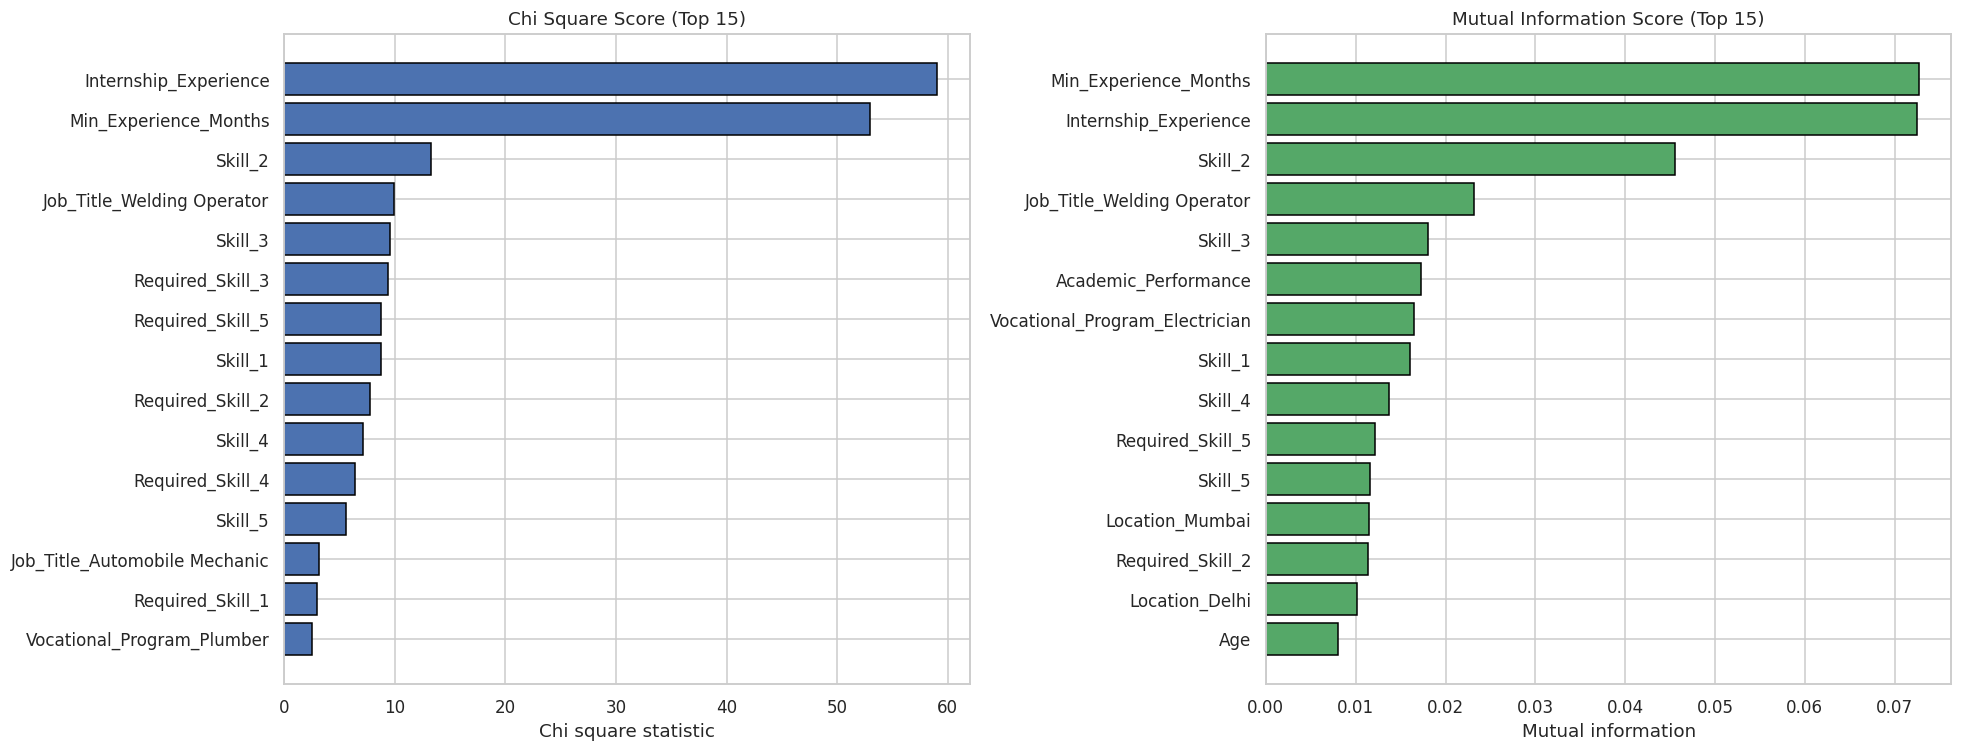

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# chi square scores for the fifteen highest scoring features
chi_plot = selection.sort_values('Chi square score', ascending=True).tail(15)
axes[0].barh(chi_plot['Feature'], chi_plot['Chi square score'], color='#4C72B0', edgecolor='black')
axes[0].set_title('Chi Square Score (Top 15)')
axes[0].set_xlabel('Chi square statistic')

# mutual information scores for the fifteen highest scoring features
mi_plot = selection.sort_values('Mutual information', ascending=True).tail(15)
axes[1].barh(mi_plot['Feature'], mi_plot['Mutual information'], color='#55A868', edgecolor='black')
axes[1].set_title('Mutual Information Score (Top 15)')
axes[1].set_xlabel('Mutual information')

plt.tight_layout()
plt.savefig('figures/fig06_feature_selection.png', bbox_inches='tight')
plt.show()

### What the Code Does

Two horizontal bar charts show the fifteen highest scoring features under the chi square test and under mutual information.

### Feature Score Findings

Internship_Experience (59.02) and Min_Experience_Months (53.00) have chi square scores about four times higher than any other feature, and the same two features lead on mutual information (0.0725 and 0.0727). The next tier is a cluster of skill scores and required skill levels. No demographic feature appears near the top of either chart.

## 7. Model Training and Hyperparameter Tuning

The five supervised classifiers from the proposal are trained: logistic regression as the linear baseline, a decision tree, a random forest, XGBoost (Chen and Guestrin, 2016) and a support vector machine. Each is placed in the same three stage pipeline:

1. **Preprocess:** one hot encoding and standard scaling (Section 5.3)
2. **Resample:** SMOTE on the training portion of each fold only (Section 5.4)
3. **Model:** the classifier being tuned

Each pipeline is tuned with GridSearchCV, which tries every combination of the listed hyperparameter values and scores each one using stratified five fold cross validation on the training set. Stratification keeps the class balance the same in every fold. The F1 score is used to choose the best combination because, unlike accuracy, it cannot be inflated by predicting the majority class (Imani et al., 2026). Placing SMOTE inside the pipeline means it is reapplied within every fold, so the records each fold is scored on never contain synthetic data.

**Research link:** This section carries out Objective 2 and prepares the comparison that answers RQ2 and tests H2.

In [21]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# each model is paired with the grid of hyperparameter values searched for it
model_specs = {
    'Logistic Regression': (
        LogisticRegression(max_iter=5000, random_state=RANDOM_STATE),
        {'model__C': [0.01, 0.1, 1, 10]}),
    'Decision Tree': (
        DecisionTreeClassifier(random_state=RANDOM_STATE),
        {'model__max_depth': [3, 5, 8, None], 'model__min_samples_split': [2, 10, 20]}),
    'Random Forest': (
        RandomForestClassifier(random_state=RANDOM_STATE),
        {'model__n_estimators': [200, 400], 'model__max_depth': [None, 10, 20],
         'model__min_samples_split': [2, 5]}),
    'XGBoost': (
        XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss'),
        {'model__n_estimators': [200, 400], 'model__max_depth': [3, 5, 7],
         'model__learning_rate': [0.05, 0.1]}),
    'Support Vector Machine': (
        SVC(probability=True, random_state=RANDOM_STATE),
        {'model__C': [0.1, 1, 10], 'model__gamma': ['scale', 0.01]}),
}

best_models, tuning_rows = {}, []
for name, (estimator, grid) in model_specs.items():
    pipeline = ImbPipeline(steps=[
        ('preprocess', preprocessor),
        ('smote', SMOTE(random_state=RANDOM_STATE)),
        ('model', estimator)
    ])
    search = GridSearchCV(pipeline, grid, scoring='f1', cv=cv, n_jobs=-1, refit=True)
    search.fit(X_train, y_train)
    best_models[name] = search.best_estimator_
    tuning_rows.append({
        'Model': name,
        'Combinations tested': len(search.cv_results_['params']),
        'Best hyperparameters': {k.replace('model__', ''): v for k, v in search.best_params_.items()},
        'Best mean CV F1': round(search.best_score_, 4)
    })
    print(f'{name:<24} best CV F1 = {search.best_score_:.4f}')

tuning_results = pd.DataFrame(tuning_rows)
tuning_results.to_csv('results/table_hyperparameter_tuning.csv', index=False)
tuning_results

Logistic Regression      best CV F1 = 0.7533


Decision Tree            best CV F1 = 0.6892


Random Forest            best CV F1 = 0.7439


XGBoost                  best CV F1 = 0.8362


Support Vector Machine   best CV F1 = 0.7911


,Model,Combinations tested,Best hyperparameters,Best mean CV F1
0,Logistic Regression,4,{'C': 0.01},0.7533
1,Decision Tree,12,"{'max_depth': 8, 'min_samples_split': 2}",0.6892
2,Random Forest,12,"{'max_depth': 10, 'min_samples_split': 5, 'n_e...",0.7439
3,XGBoost,12,"{'learning_rate': 0.05, 'max_depth': 5, 'n_est...",0.8362
4,Support Vector Machine,6,"{'C': 1, 'gamma': 'scale'}",0.7911


### What the Code Does

For each of the five models, the code builds an imbalanced learn pipeline that chains preprocessing, SMOTE and the classifier, so all three steps are repeated inside every cross validation fold. GridSearchCV fits the pipeline with every combination in the model's grid on five stratified folds, keeps the combination with the highest mean F1, and refits it on the whole training set. The tuned model, its hyperparameters and its cross validation F1 are stored.

### Tuning Findings

Forty six hyperparameter combinations were evaluated across the five models, each on five folds, giving 230 fitted pipelines. The selected settings are the analysis parameters reported in the research report:

<table><thead><tr><th align='left'>Model</th><th align='left'>Selected hyperparameters</th><th align='left'>Best mean CV F1</th></tr></thead><tbody><tr><td align='left'>Logistic Regression</td><td align='left'>C = 0.01</td><td align='left'>0.7533</td></tr><tr><td align='left'>Decision Tree</td><td align='left'>max_depth = 8, min_samples_split = 2</td><td align='left'>0.6892</td></tr><tr><td align='left'>Random Forest</td><td align='left'>n_estimators = 200, max_depth = 10, min_samples_split = 5</td><td align='left'>0.7439</td></tr><tr><td align='left'>XGBoost</td><td align='left'>n_estimators = 400, max_depth = 5, learning_rate = 0.05</td><td align='left'>0.8362</td></tr><tr><td align='left'>Support Vector Machine</td><td align='left'>C = 1, gamma = scale (RBF kernel)</td><td align='left'>0.7911</td></tr></tbody></table>

XGBoost achieved the highest cross validation F1 (0.836) and the decision tree the lowest (0.689). Logistic regression selected the strongest regularisation on offer, C = 0.01, which means a simpler linear boundary generalised best. The random forest preferred a depth limit of 10 over unlimited depth, which restricts how far each tree can overfit.

## 8. Model Evaluation and Comparison

Every tuned model is now evaluated once on the held out test set, which none of them has seen during training or tuning. Seven metrics are reported, following the evaluation design in Section 9.4 of the proposal:

1. **Accuracy:** the share of all predictions that were correct. Reported for completeness but not relied on, because it is inflated by the majority class.
2. **Precision:** of the trainees predicted to be matched, the share who really were.
3. **Recall:** of the trainees who really were matched, the share the model found.
4. **F1 score:** the balance between precision and recall.
5. **Matthews Correlation Coefficient (MCC):** a single score between minus one and one that uses all four cells of the confusion matrix and stays honest under class imbalance (Imani et al., 2026).
6. **PR AUC:** the area under the precision recall curve, which focuses on performance on the matched class.
7. **ROC AUC:** the area under the ROC curve, reported for comparability with other studies.

**Research link:** This section completes Objective 2, answers RQ2 and tests H2.

### 8.1 Majority Class Baseline

Before evaluating the real models, a baseline that predicts "no match" for every trainee is scored. This shows what a model that has learned nothing would achieve, and it reproduces on this dataset the failure observed in Xue (2025), where a support vector machine reported 67.67 percent accuracy with a recall and F1 score of zero.

In [22]:
baseline = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
y_pred_base = baseline.predict(X_test)

print('Majority class baseline (always predicts no match)')
print(f'  Accuracy:  {accuracy_score(y_test, y_pred_base):.4f}')
print(f'  Precision: {precision_score(y_test, y_pred_base, zero_division=0):.4f}')
print(f'  Recall:    {recall_score(y_test, y_pred_base):.4f}')
print(f'  F1 score:  {f1_score(y_test, y_pred_base):.4f}')
print(f'  MCC:       {matthews_corrcoef(y_test, y_pred_base):.4f}')

Majority class baseline (always predicts no match)
  Accuracy:  0.6833
  Precision: 0.0000
  Recall:    0.0000
  F1 score:  0.0000
  MCC:       0.0000


### What the Code Does

DummyClassifier with the most_frequent strategy ignores the features entirely and always predicts the most common class in the training data, which is no match. It is scored on the test set with the same metrics used for the real models.

### Baseline Findings

The baseline reaches 68.33 percent accuracy while its precision, recall, F1 and MCC are all zero. It finds none of the 178 matched trainees in the test set. This reproduces the failure documented in Xue (2025) and shows concretely why this study does not judge models on accuracy: a model with no predictive ability at all scores 68 percent. A useful model must score clearly above zero on F1 and MCC.

### 8.2 Test Set Performance of the Five Models

In [23]:
def evaluate(model, X_eval, y_eval):
    # predicted classes and the predicted probability of a match
    pred = model.predict(X_eval)
    prob = model.predict_proba(X_eval)[:, 1]
    return {
        'Accuracy': accuracy_score(y_eval, pred),
        'Precision': precision_score(y_eval, pred),
        'Recall': recall_score(y_eval, pred),
        'F1': f1_score(y_eval, pred),
        'MCC': matthews_corrcoef(y_eval, pred),
        'PR AUC': average_precision_score(y_eval, prob),
        'ROC AUC': roc_auc_score(y_eval, prob)
    }

predictions, probabilities, results_rows = {}, {}, []
for name, model in best_models.items():
    predictions[name] = model.predict(X_test)
    probabilities[name] = model.predict_proba(X_test)[:, 1]
    row = {'Model': name}
    row.update(evaluate(model, X_test, y_test))
    results_rows.append(row)

results = pd.DataFrame(results_rows).sort_values(['MCC', 'F1'], ascending=False).reset_index(drop=True)
results.to_csv('results/table_test_performance.csv', index=False)
results.round(4)

,Model,Accuracy,Precision,Recall,F1,MCC,PR AUC,ROC AUC
0,XGBoost,0.8932,0.8138,0.8596,0.8361,0.7576,0.9093,0.9573
1,Support Vector Machine,0.8399,0.7245,0.7978,0.7594,0.6414,0.8399,0.9242
2,Random Forest,0.8434,0.7812,0.7022,0.7396,0.6300,0.8227,0.9233
3,Logistic Regression,0.8149,0.6637,0.8427,0.7426,0.6117,0.7822,0.9022
4,Decision Tree,0.7883,0.6347,0.7809,0.7003,0.5462,0.6144,0.8246


### What the Code Does

The evaluate function takes a fitted model, predicts the class and the match probability for every test record, and calculates all seven metrics. It is run for each tuned model, and the results are sorted by MCC with F1 used to break ties.

### Test Set Findings

XGBoost was the best performing model on every metric: F1 0.836, MCC 0.758, PR AUC 0.909, ROC AUC 0.957 and accuracy 0.893. The support vector machine ranked second on MCC (0.641), followed by random forest (0.630), logistic regression (0.612) and the decision tree (0.546).

The ranking shifts depending on the metric. Logistic regression had a slightly higher F1 than random forest (0.743 against 0.740) because it found more of the matched trainees (recall 0.843 against 0.702), but random forest was more precise (0.781 against 0.664) and had the higher MCC. A single metric would hide this trade off, which is why the proposal committed to reporting several.

Every model comfortably beat the majority class baseline on F1 and MCC. ROC AUC values (0.825 to 0.957) were consistently higher than PR AUC values (0.614 to 0.909), which illustrates the optimistic reading of ROC AUC under imbalance described by Imani et al. (2026).

**Research link (RQ2):** XGBoost is the algorithm that achieved the highest predictive performance on the employment outcome.

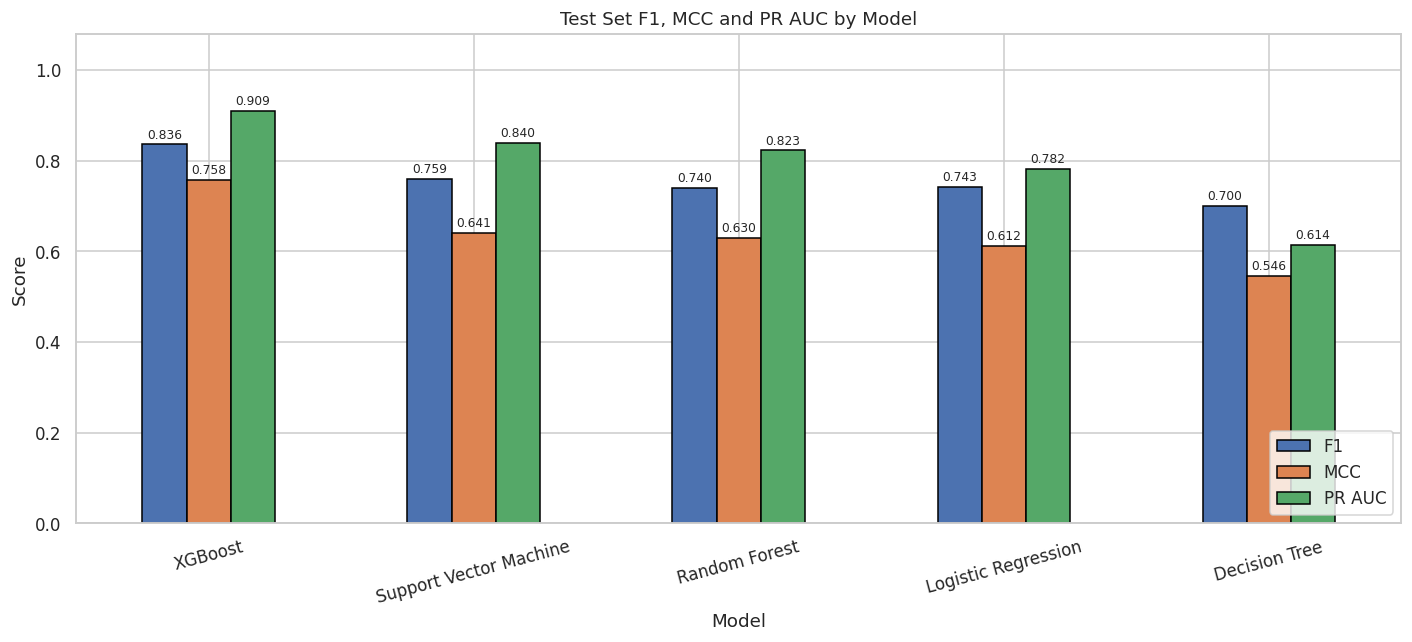

In [24]:
# grouped bar chart of the three imbalance robust metrics for every model
plot_df = results.set_index('Model')[['F1', 'MCC', 'PR AUC']]
ax = plot_df.plot(kind='bar', figsize=(13, 6), color=['#4C72B0', '#DD8452', '#55A868'], edgecolor='black')
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', fontsize=8, padding=2)
plt.title('Test Set F1, MCC and PR AUC by Model')
plt.ylabel('Score')
plt.ylim(0, 1.08)
plt.xticks(rotation=15)
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('figures/fig07_model_comparison.png', bbox_inches='tight')
plt.show()

### What the Code Does

The results table is reshaped to show F1, MCC and PR AUC for each model as grouped bars, with each value printed above its bar.

### Comparison Chart Findings

XGBoost is clearly ahead on all three measures. The gap is largest on MCC, where XGBoost (0.758) leads the second placed support vector machine (0.641) by 0.116. The decision tree is the weakest on all three, and its PR AUC (0.614) is far below the other models.

### 8.3 Confusion Matrices

A confusion matrix splits each model's test predictions into four counts. The top left cell holds correctly predicted non matches, the bottom right holds correctly predicted matches, the top right holds trainees wrongly predicted to be matched (false positives) and the bottom left holds matched trainees the model missed (false negatives). In this setting a false negative means a trainee who would find work is predicted not to, which could lead to support being withdrawn from someone the programme was actually helping.

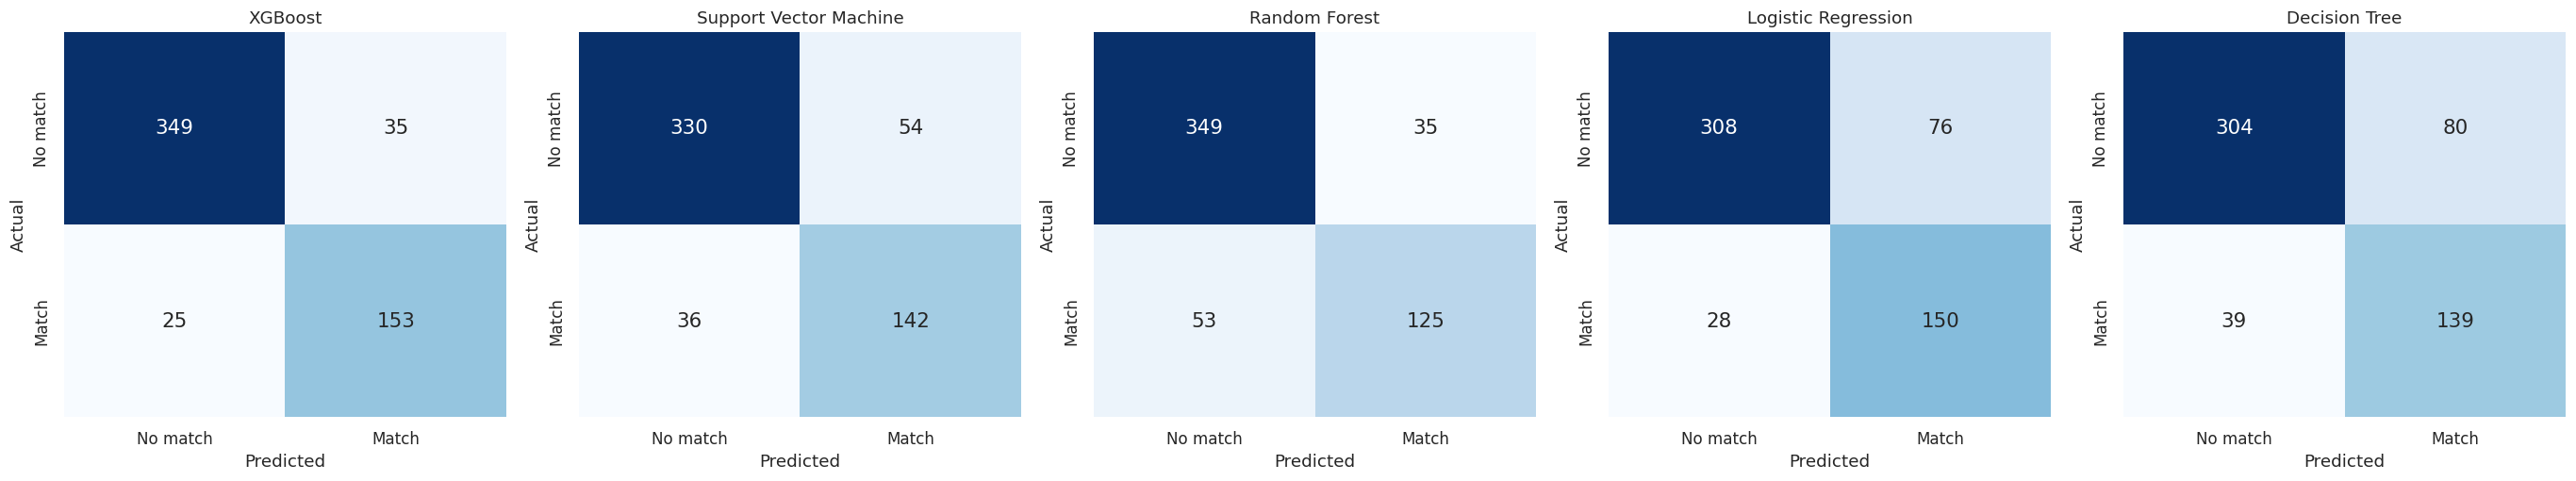

In [25]:
fig, axes = plt.subplots(1, 5, figsize=(25, 4.8))
for ax, name in zip(axes, results['Model']):
    cm = confusion_matrix(y_test, predictions[name])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['No match', 'Match'], yticklabels=['No match', 'Match'],
                annot_kws={'size': 14})
    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.tight_layout()
plt.savefig('figures/fig08_confusion_matrices.png', bbox_inches='tight')
plt.show()

### What the Code Does

For each model, confusion_matrix counts the four possible outcomes on the test set, and a heatmap displays them with the count printed in each cell.

### Confusion Matrix Findings

<table><thead><tr><th align='left'>Model</th><th align='left'>True negatives</th><th align='left'>False positives</th><th align='left'>False negatives</th><th align='left'>True positives</th></tr></thead><tbody><tr><td align='left'>XGBoost</td><td align='left'>349</td><td align='left'>35</td><td align='left'>25</td><td align='left'>153</td></tr><tr><td align='left'>Support Vector Machine</td><td align='left'>330</td><td align='left'>54</td><td align='left'>36</td><td align='left'>142</td></tr><tr><td align='left'>Random Forest</td><td align='left'>349</td><td align='left'>35</td><td align='left'>53</td><td align='left'>125</td></tr><tr><td align='left'>Logistic Regression</td><td align='left'>308</td><td align='left'>76</td><td align='left'>28</td><td align='left'>150</td></tr><tr><td align='left'>Decision Tree</td><td align='left'>304</td><td align='left'>80</td><td align='left'>39</td><td align='left'>139</td></tr></tbody></table>

XGBoost missed the fewest matched trainees (25 of 178) and made the joint fewest false positives (35). Random forest made the same number of false positives but missed 53 matched trainees, more than twice as many as XGBoost, which explains its lower recall. Logistic regression and the decision tree made the most false positives (76 and 80). Logistic regression nonetheless missed only 28 matched trainees, so its errors lean towards predicting a match.

### 8.4 Classification Reports

The classification report gives precision, recall and F1 separately for each class, which shows whether a model performs evenly on matched and unmatched trainees or only on the larger class.

In [26]:
for name in results['Model']:
    print('=' * 62)
    print(name)
    print('=' * 62)
    print(classification_report(y_test, predictions[name], target_names=['No match', 'Match'], digits=3))

XGBoost
              precision    recall  f1-score   support

    No match      0.933     0.909     0.921       384
       Match      0.814     0.860     0.836       178

    accuracy                          0.893       562
   macro avg      0.873     0.884     0.878       562
weighted avg      0.895     0.893     0.894       562

Support Vector Machine
              precision    recall  f1-score   support

    No match      0.902     0.859     0.880       384
       Match      0.724     0.798     0.759       178

    accuracy                          0.840       562
   macro avg      0.813     0.829     0.820       562
weighted avg      0.846     0.840     0.842       562

Random Forest
              precision    recall  f1-score   support

    No match      0.868     0.909     0.888       384
       Match      0.781     0.702     0.740       178

    accuracy                          0.843       562
   macro avg      0.825     0.806     0.814       562
weighted avg      0.841     0

### What the Code Does

classification_report prints precision, recall and F1 for each class separately, together with the overall accuracy and the macro and weighted averages.

### Classification Report Findings

Every model performs better on the non match class than on the match class. This is expected, because the non match class is larger and therefore easier to learn. XGBoost has the most even performance across the two classes (F1 0.921 for non match and 0.836 for match). The decision tree has the widest gap (0.836 against 0.700), meaning it struggles most with the minority class.

### 8.5 ROC Curves and Precision Recall Curves

The ROC curve plots the true positive rate against the false positive rate at every possible decision threshold. The precision recall curve plots precision against recall, and under class imbalance it is the more informative of the two because it concentrates on the matched class (Imani et al., 2026). On the ROC plot the dotted diagonal shows a random classifier. On the precision recall plot the dotted horizontal line shows the share of matched records, which is what a random classifier would achieve.

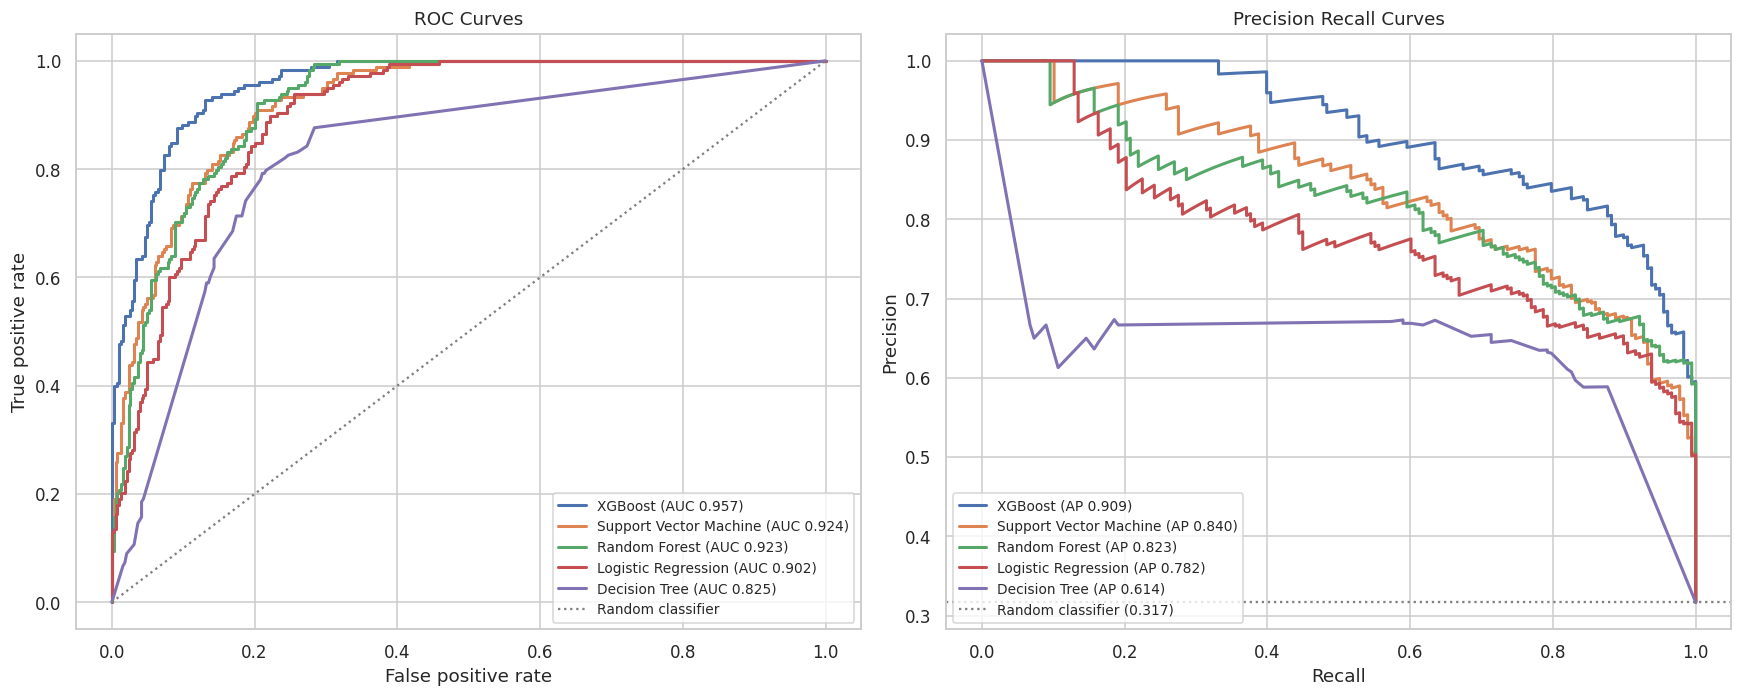

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for name in results['Model']:
    fpr, tpr, _ = roc_curve(y_test, probabilities[name])
    axes[0].plot(fpr, tpr, linewidth=2, label=f'{name} (AUC {roc_auc_score(y_test, probabilities[name]):.3f})')
    prec, rec, _ = precision_recall_curve(y_test, probabilities[name])
    axes[1].plot(rec, prec, linewidth=2, label=f'{name} (AP {average_precision_score(y_test, probabilities[name]):.3f})')

axes[0].plot([0, 1], [0, 1], color='grey', linestyle='dotted', label='Random classifier')
axes[0].set_title('ROC Curves')
axes[0].set_xlabel('False positive rate')
axes[0].set_ylabel('True positive rate')
axes[0].legend(loc='lower right', fontsize=9)

axes[1].axhline(y_test.mean(), color='grey', linestyle='dotted', label=f'Random classifier ({y_test.mean():.3f})')
axes[1].set_title('Precision Recall Curves')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend(loc='lower left', fontsize=9)

plt.tight_layout()
plt.savefig('figures/fig09_roc_pr_curves.png', bbox_inches='tight')
plt.show()

### What the Code Does

For each model, roc_curve and precision_recall_curve calculate points on the curve at every decision threshold from the predicted probabilities. The curves are drawn together with the random classifier reference lines, and the area under each curve is shown in the legend.

### Curve Findings

XGBoost's curve sits above every other model's across almost the entire range on both plots. On the precision recall plot the random classifier line sits at 0.317, the share of matched records, and every model lies well above it. The decision tree's curves are visibly lower and more angular, because a single tree produces only a small number of distinct probability values.

### 8.6 Cross Validation Stability and Statistical Comparison

A single test set can favour one model by chance. To check that the ranking is stable, each tuned pipeline is evaluated again with stratified five fold cross validation on the training data, recording F1 and MCC in every fold. Training F1 is also recorded so that overfitting can be detected: a model scoring far higher on training data than on validation folds has memorised rather than learned.

Paired t tests then compare each ensemble model against logistic regression fold by fold. With only five folds these tests have limited statistical power, so they are read alongside the size of the difference, not instead of it.

In [28]:
scoring = {'f1': 'f1', 'mcc': make_scorer(matthews_corrcoef)}
cv_rows, fold_scores = [], {}
for name, model in best_models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, return_train_score=True, n_jobs=-1)
    fold_scores[name] = scores
    cv_rows.append({
        'Model': name,
        'CV F1 mean': scores['test_f1'].mean(),
        'CV F1 std': scores['test_f1'].std(),
        'CV MCC mean': scores['test_mcc'].mean(),
        'CV MCC std': scores['test_mcc'].std(),
        'Train F1 mean': scores['train_f1'].mean(),
        'Train minus CV F1': scores['train_f1'].mean() - scores['test_f1'].mean()
    })
cv_results = pd.DataFrame(cv_rows).sort_values('CV MCC mean', ascending=False).reset_index(drop=True)
cv_results.to_csv('results/table_cross_validation.csv', index=False)
cv_results.round(4)

,Model,CV F1 mean,CV F1 std,CV MCC mean,CV MCC std,Train F1 mean,Train minus CV F1
0,XGBoost,0.8362,0.0129,0.7596,0.0187,1.0000,0.1638
1,Support Vector Machine,0.7911,0.0147,0.6910,0.0224,0.9337,0.1426
2,Random Forest,0.7439,0.0305,0.6350,0.0439,0.9923,0.2484
3,Logistic Regression,0.7533,0.0317,0.6286,0.0496,0.7636,0.0103
4,Decision Tree,0.6892,0.0229,0.5340,0.0327,0.8788,0.1896


### What the Code Does

cross_validate refits each tuned pipeline on five stratified folds of the training data. For each fold it records F1 and MCC on the held out part and F1 on the part used for training. The table shows the mean and standard deviation across the five folds and the difference between training and validation F1.

### Cross Validation Findings

The ranking from the test set is confirmed. XGBoost had the highest mean MCC (0.760) and F1 (0.836), with the smallest spread across folds (F1 standard deviation 0.013). The support vector machine was again second. Random forest and logistic regression were close (MCC 0.635 against 0.629), and the decision tree was last.

The gap between training and validation F1 shows how much each model overfits. Logistic regression barely overfits (0.010). XGBoost fits the training data perfectly (training F1 1.000), a gap of 0.164, and random forest has the largest gap (0.248). Even so, XGBoost's validation scores are the highest and the most stable, and its test F1 (0.836) matches its cross validation F1 (0.836), so its close fit to the training data did not hurt its performance on unseen data.

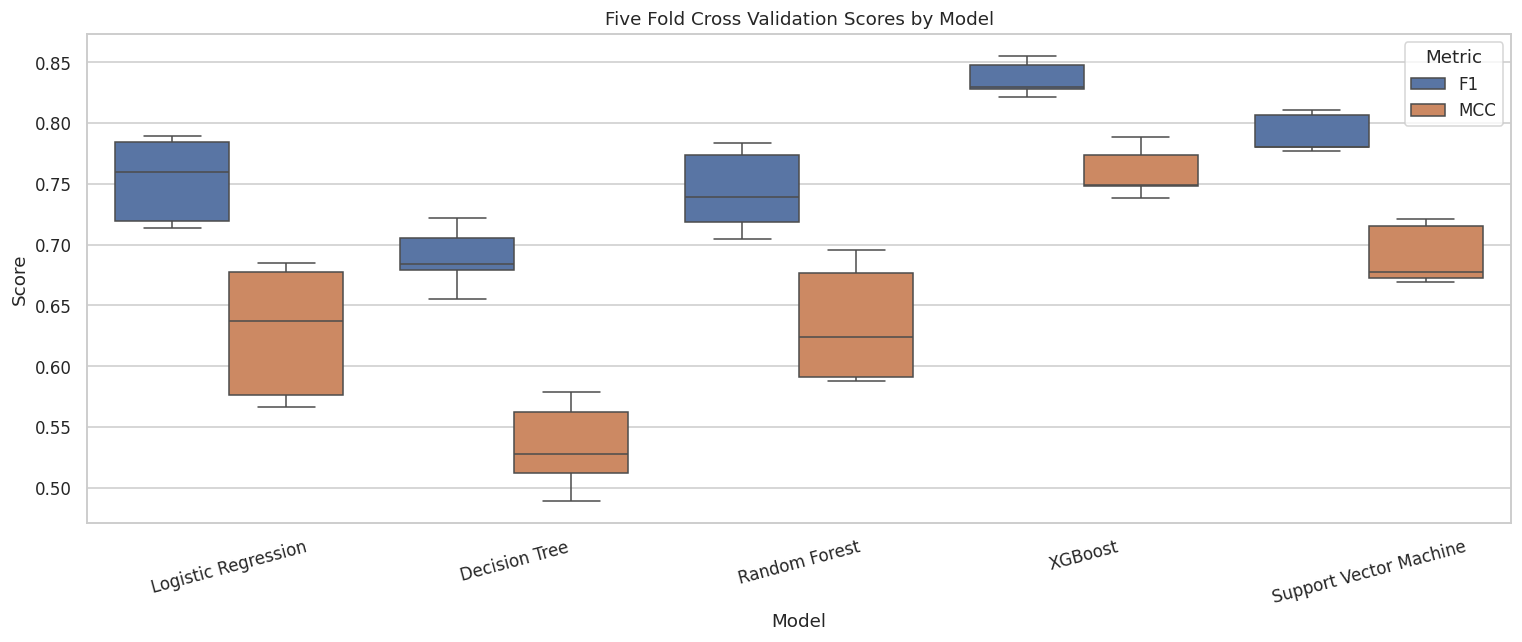

Paired t tests against Logistic Regression (same folds)
  Random Forest  F1   mean difference -0.0093   t = -0.735   p = 0.5030
  Random Forest  MCC  mean difference +0.0064   t =  0.401   p = 0.7088
  XGBoost        F1   mean difference +0.0829   t =  5.509   p = 0.0053
  XGBoost        MCC  mean difference +0.1310   t =  5.631   p = 0.0049


In [29]:
# box plot of fold by fold F1 and MCC for each model
fold_long = pd.concat([
    pd.DataFrame({'Model': name, 'Metric': metric.upper(), 'Score': s[f'test_{metric}']})
    for name, s in fold_scores.items() for metric in ['f1', 'mcc']
])
plt.figure(figsize=(14, 6))
sns.boxplot(data=fold_long, x='Model', y='Score', hue='Metric', palette=['#4C72B0', '#DD8452'])
plt.title('Five Fold Cross Validation Scores by Model')
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig('figures/fig10_cv_stability.png', bbox_inches='tight')
plt.show()

# paired t tests: each ensemble model compared with logistic regression on the same five folds
print('Paired t tests against Logistic Regression (same folds)')
for ensemble in ['Random Forest', 'XGBoost']:
    for metric in ['f1', 'mcc']:
        a = fold_scores[ensemble][f'test_{metric}']
        b = fold_scores['Logistic Regression'][f'test_{metric}']
        t_stat, p_val = stats.ttest_rel(a, b)
        mean_difference = np.mean(a) - np.mean(b)
        print(f'  {ensemble:<14} {metric.upper():<4} mean difference {mean_difference:+.4f}   t = {t_stat:6.3f}   p = {p_val:.4f}')

### What the Code Does

The first part reshapes the fold scores and draws a box plot of F1 and MCC for each model. The second part runs a paired t test comparing each ensemble model with logistic regression, pairing scores from the same fold so that the comparison is like for like.

### Statistical Comparison Findings

XGBoost outperformed logistic regression by 0.083 on F1 and 0.131 on MCC, and both differences were statistically significant (p = 0.005). Random forest did not differ significantly from logistic regression: its mean F1 was 0.009 lower (p = 0.503) and its mean MCC 0.006 higher (p = 0.709). The box plot shows XGBoost's folds sitting clearly above the rest with little spread, while the random forest and logistic regression boxes overlap almost completely.

### 8.7 Hypothesis 2 Verdict

In [30]:
lr_row = results.set_index('Model').loc['Logistic Regression']
h2_rows = []
for ensemble in ['Random Forest', 'XGBoost']:
    e_row = results.set_index('Model').loc[ensemble]
    h2_rows.append({
        'Ensemble model': ensemble,
        'F1 (ensemble)': round(e_row['F1'], 4), 'F1 (logistic)': round(lr_row['F1'], 4),
        'MCC (ensemble)': round(e_row['MCC'], 4), 'MCC (logistic)': round(lr_row['MCC'], 4),
        'Higher on both': 'Yes' if (e_row['F1'] > lr_row['F1'] and e_row['MCC'] > lr_row['MCC']) else 'No'
    })
h2_table = pd.DataFrame(h2_rows)
h2_table

,Ensemble model,F1 (ensemble),F1 (logistic),MCC (ensemble),MCC (logistic),Higher on both
0,Random Forest,0.7396,0.7426,0.6300,0.6117,No
1,XGBoost,0.8361,0.7426,0.7576,0.6117,Yes


### What the Code Does

The code compares the test set F1 and MCC of each ensemble model with those of logistic regression, and records whether the ensemble is higher on both.

### Hypothesis 2 Verdict

H2 predicted that the ensemble methods, particularly random forest and XGBoost, would achieve higher F1 scores and MCC values than the linear classifier.

**H2 is partially supported.** XGBoost exceeded logistic regression on both metrics on the test set (F1 0.836 against 0.743, MCC 0.758 against 0.612), and the difference was statistically significant across the cross validation folds. Random forest did not: its MCC was slightly higher (0.630 against 0.612) but its F1 was slightly lower (0.740 against 0.743), and neither difference was significant. The hypothesis therefore holds for gradient boosting but not for ensemble methods in general.

A plausible explanation, examined in Section 11, is that the outcome depends on comparisons between pairs of features. Boosting builds each new tree to correct the errors of the trees before it, which lets it approximate this kind of structure more efficiently than a random forest, which averages trees that are built independently.

**Research link (O2, RQ2, H2):** Objective 2 is complete. RQ2 is answered: XGBoost achieved the highest predictive performance of the five algorithms.

## 9. Explainability with SHAP

SHAP (SHapley Additive exPlanations) explains a model's predictions by assigning each feature a value that represents its contribution to a single prediction, using a method drawn from cooperative game theory (Lundberg and Lee, 2017). Averaging the size of these values across all test records gives a global ranking of which features drive the model. Looking at the values for one record explains that individual prediction.

SHAP is applied to the best performing model from Section 8, selected on test set MCC. SHAP values are calculated on the transformed test data, so numerical features appear in standardised units and each category appears as its own one hot column.

**Research link:** This section carries out the explainability part of Objective 3, gives the model based answer to RQ1 and tests H1. It also supplies the SHAP evidence needed for RQ3.

In [31]:
best_name = results.loc[0, 'Model']
best_pipeline = best_models[best_name]
fitted_preprocessor = best_pipeline.named_steps['preprocess']
best_estimator = best_pipeline.named_steps['model']

# transform the test set with the preprocessor learned inside the best pipeline
feature_names = [n.split('__', 1)[1] for n in fitted_preprocessor.get_feature_names_out()]
X_test_shap = pd.DataFrame(fitted_preprocessor.transform(X_test), columns=feature_names, index=X_test.index)

# tree based models use the exact TreeExplainer; any other model falls back to a sampled explainer
if best_name in ['XGBoost', 'Random Forest', 'Decision Tree']:
    explainer = shap.TreeExplainer(best_estimator)
    shap_explanation = explainer(X_test_shap)
else:
    background = shap.sample(pd.DataFrame(fitted_preprocessor.transform(X_train), columns=feature_names), 100, random_state=RANDOM_STATE)
    explainer = shap.Explainer(lambda d: best_estimator.predict_proba(d)[:, 1], background)
    shap_explanation = explainer(X_test_shap)

# for random forest and decision tree, keep only the values for the match class
if shap_explanation.values.ndim == 3:
    shap_explanation = shap_explanation[:, :, 1]

shap_values = shap_explanation.values
print(f'Model explained:   {best_name}')
print(f'SHAP value matrix: {shap_values.shape[0]} test records by {shap_values.shape[1]} features')

Model explained:   XGBoost
SHAP value matrix: 562 test records by 35 features


### What the Code Does

The name of the best model is taken from the top row of the results table, which is XGBoost. Its fitted preprocessor and classifier are taken out of the pipeline, and the test set is transformed exactly as the model saw it. A TreeExplainer, which calculates exact SHAP values for tree based models, is then created and applied to the transformed test data, returning one SHAP value for every feature of every test record.

### SHAP Setup Findings

SHAP values were calculated for all 562 test records across all 35 transformed features of the XGBoost model. The values are on the log odds scale: positive values push the prediction towards a match and negative values push it away from a match.

### 9.1 Global Feature Importance

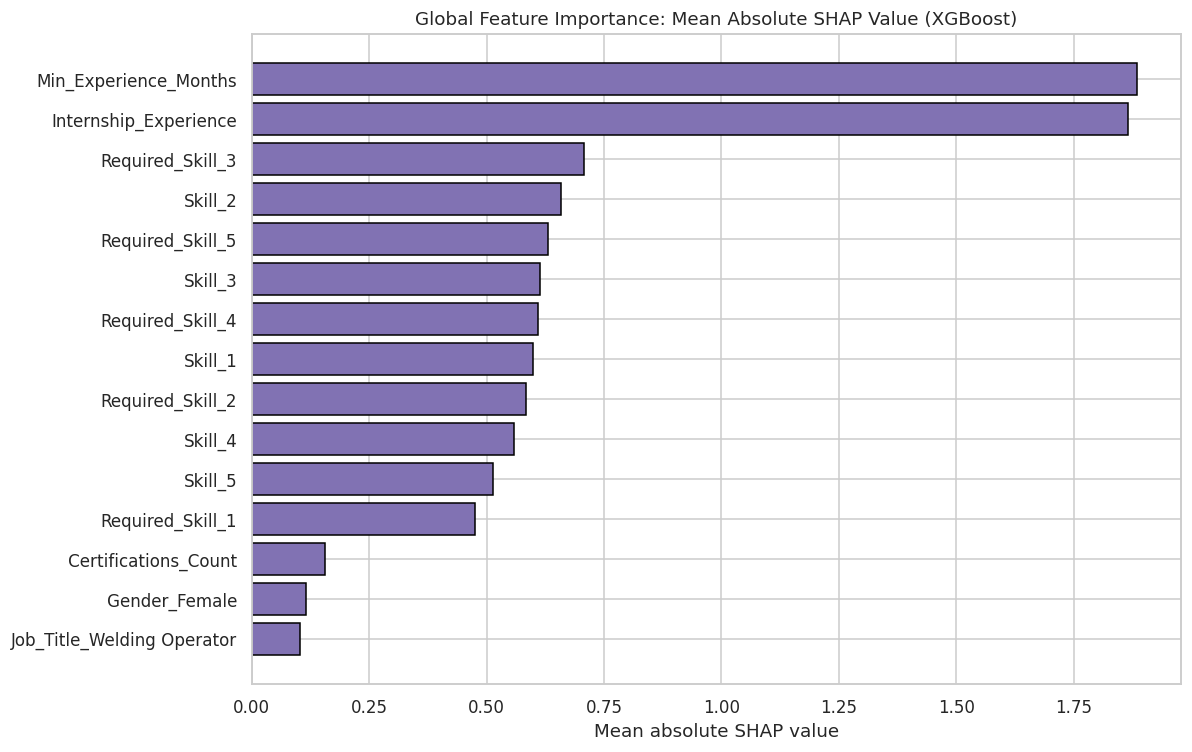

,Feature,Mean absolute SHAP,Rank,Share of total (%)
0,Min_Experience_Months,1.8852,1,17.51
1,Internship_Experience,1.8651,2,17.32
2,Required_Skill_3,0.7067,3,6.56
3,Skill_2,0.6574,4,6.11
4,Required_Skill_5,0.6309,5,5.86
5,Skill_3,0.6137,6,5.70
6,Required_Skill_4,0.6100,7,5.67
7,Skill_1,0.5980,8,5.55
8,Required_Skill_2,0.5849,9,5.43
9,Skill_4,0.5594,10,5.20


In [32]:
# mean absolute SHAP value for every transformed feature
global_importance = pd.DataFrame({
    'Feature': feature_names,
    'Mean absolute SHAP': np.abs(shap_values).mean(axis=0)
}).sort_values('Mean absolute SHAP', ascending=False).reset_index(drop=True)
global_importance['Rank'] = global_importance.index + 1
global_importance['Share of total (%)'] = (global_importance['Mean absolute SHAP'] /
                                           global_importance['Mean absolute SHAP'].sum() * 100).round(2)
global_importance.to_csv('results/table_shap_global_importance.csv', index=False)

top = global_importance.head(15).iloc[::-1]
plt.figure(figsize=(11, 7))
plt.barh(top['Feature'], top['Mean absolute SHAP'], color='#8172B3', edgecolor='black')
plt.title(f'Global Feature Importance: Mean Absolute SHAP Value ({best_name})')
plt.xlabel('Mean absolute SHAP value')
plt.tight_layout()
plt.savefig('figures/fig11_shap_global_importance.png', bbox_inches='tight')
plt.show()

global_importance.head(15).round(4)

### What the Code Does

The code averages the absolute SHAP value of each feature across all test records, ranks the features, calculates each feature's share of the total, and plots the top fifteen.

### Global Importance Findings

Two features dominate: Min_Experience_Months (17.51 percent of total importance) and Internship_Experience (17.32 percent). Together they account for more than a third of the model's reasoning. The next ten places are filled entirely by the five skill scores and the five required skill levels, each contributing between 4.41 and 6.56 percent. Below them importance drops sharply: Certifications_Count is 13th at 1.45 percent and Gender_Female 14th at 1.08 percent.

### 9.2 SHAP Summary Plot

The summary plot shows every test record as a dot for each feature. The horizontal position shows whether that feature pushed the prediction towards a match (right) or away from a match (left), and the colour shows whether the feature value was high (red) or low (blue). It therefore shows the direction of each effect as well as its size.

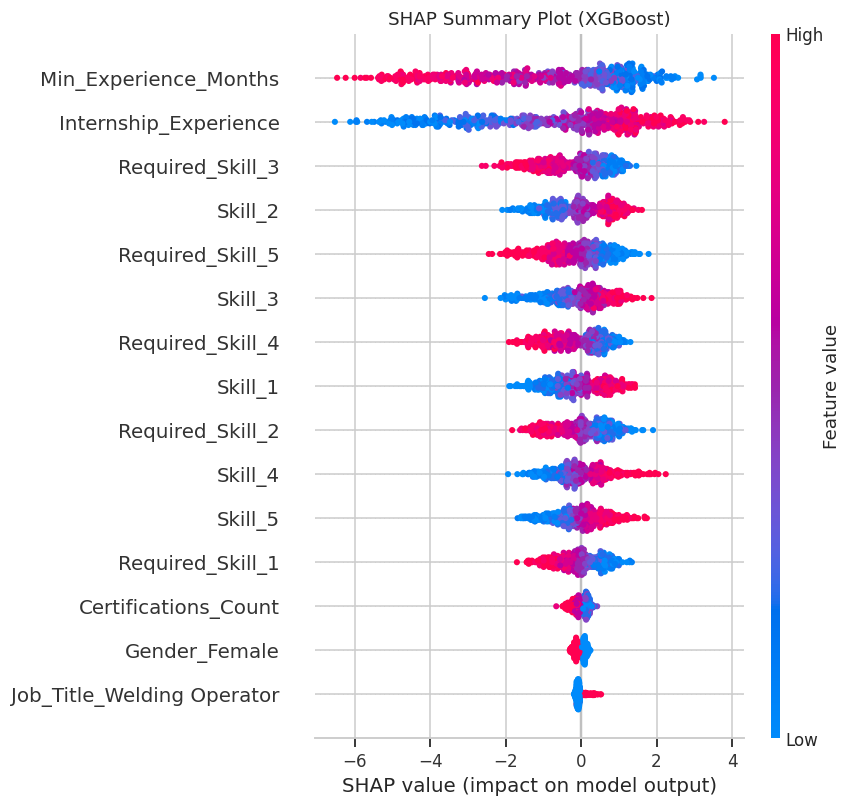

In [33]:
shap.summary_plot(shap_values, X_test_shap, max_display=15, show=False)
plt.title(f'SHAP Summary Plot ({best_name})')
plt.tight_layout()
plt.savefig('figures/fig12_shap_summary.png', bbox_inches='tight')
plt.show()

### What the Code Does

summary_plot draws a beeswarm chart for the top fifteen features. Each dot is one test record, placed by its SHAP value and coloured by the value of the feature for that record.

### Summary Plot Findings

The plot shows the direction of each effect. For Internship_Experience, high values (red) sit on the right and low values (blue) on the left, so more internship experience pushes towards a match. For Min_Experience_Months the pattern is reversed: a high experience requirement pushes strongly away from a match, with SHAP values reaching about minus six.

The skill scores behave like internship experience, where higher is better, and every required skill level behaves like the minimum experience requirement, where higher is worse. The model has therefore learned that the outcome depends on how the trainee compares with the job, not on the trainee's characteristics alone.

### 9.3 Importance by Theoretical Construct

To connect the SHAP results to the theoretical framework, the one hot columns are first added back together under their original field, and the fields are then grouped into the four constructs defined in Section 3.1. This shows how much of the model's reasoning comes from training related human capital, from second level skill indicators, from the job requirement profile and from demographic attributes.

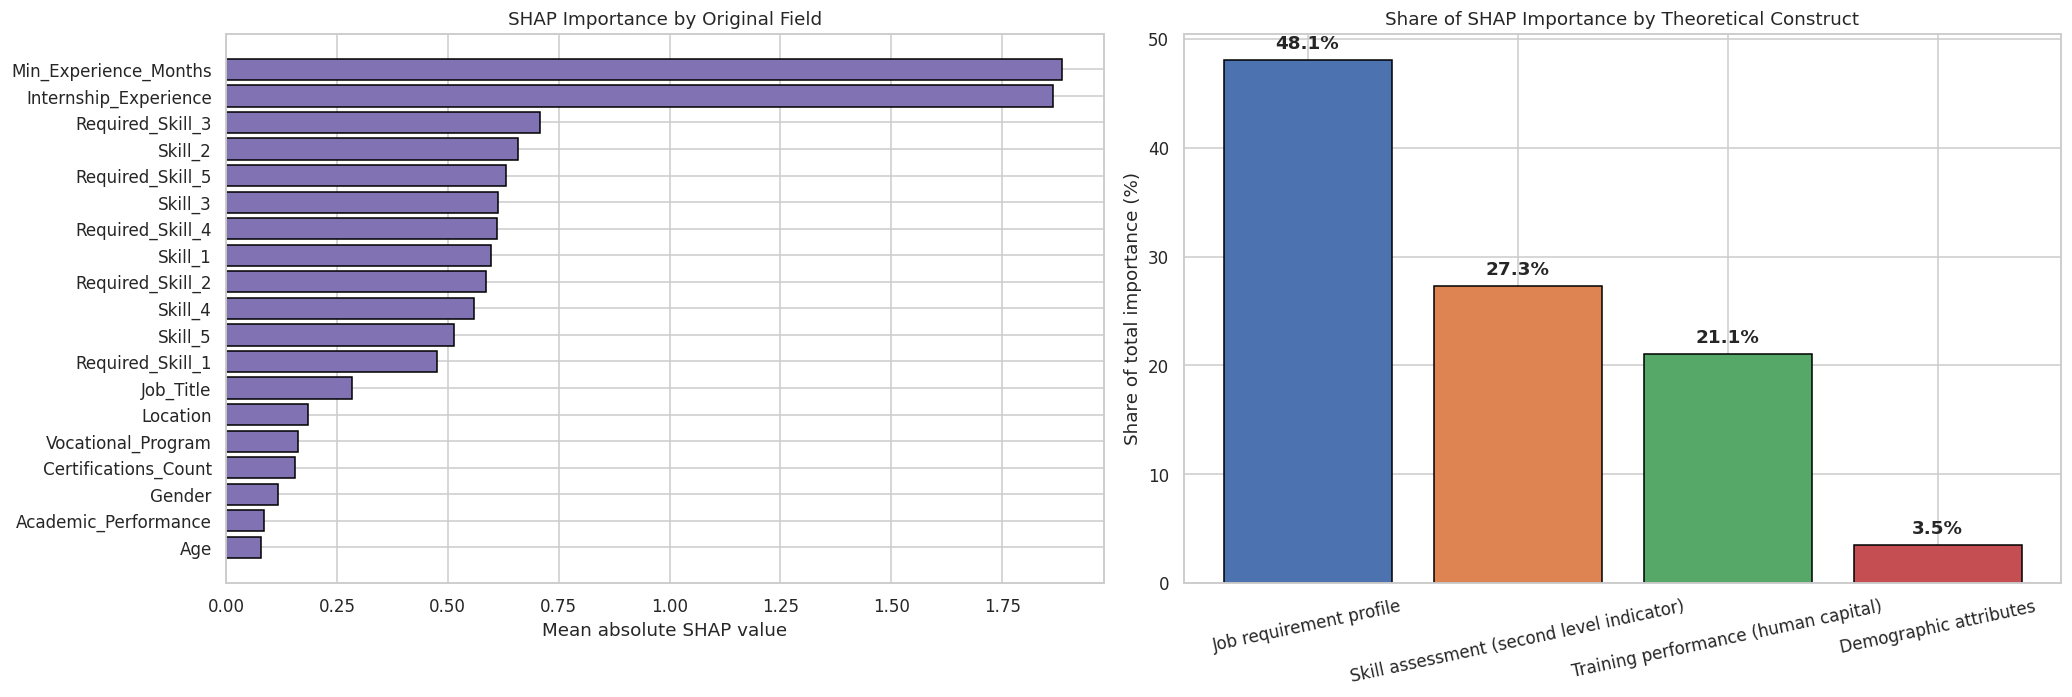

,Rank,Field,Construct,Mean absolute SHAP,Share of total (%)
0,1,Min_Experience_Months,Job requirement profile,1.8852,17.51
1,2,Internship_Experience,Training performance (human capital),1.8651,17.32
2,3,Required_Skill_3,Job requirement profile,0.7067,6.56
3,4,Skill_2,Skill assessment (second level indicator),0.6574,6.11
4,5,Required_Skill_5,Job requirement profile,0.6309,5.86
5,6,Skill_3,Skill assessment (second level indicator),0.6137,5.70
6,7,Required_Skill_4,Job requirement profile,0.6100,5.67
7,8,Skill_1,Skill assessment (second level indicator),0.5980,5.55
8,9,Required_Skill_2,Job requirement profile,0.5849,5.43
9,10,Skill_4,Skill assessment (second level indicator),0.5594,5.20


,Construct,Mean absolute SHAP,Share of total (%)
0,Job requirement profile,5.1755,48.07
1,Skill assessment (second level indicator),2.9425,27.33
2,Training performance (human capital),2.2687,21.07
3,Demographic attributes,0.3798,3.53


In [34]:
def original_field(transformed_name):
    # map a one hot column such as Gender_Male back to its original field Gender
    for col in categorical_cols:
        if transformed_name.startswith(col + '_'):
            return col
    return transformed_name

construct_map = {
    'Academic_Performance': 'Training performance (human capital)',
    'Certifications_Count': 'Training performance (human capital)',
    'Internship_Experience': 'Training performance (human capital)',
    'Vocational_Program': 'Training performance (human capital)',
    **{c: 'Skill assessment (second level indicator)' for c in skill_cols},
    **{c: 'Job requirement profile' for c in req_cols},
    'Min_Experience_Months': 'Job requirement profile',
    'Job_Title': 'Job requirement profile',
    'Age': 'Demographic attributes',
    'Gender': 'Demographic attributes',
    'Location': 'Demographic attributes',
}

field_importance = (global_importance.assign(Field=global_importance['Feature'].map(original_field))
                    .groupby('Field')['Mean absolute SHAP'].sum().sort_values(ascending=False).reset_index())
field_importance['Rank'] = field_importance.index + 1
field_importance['Construct'] = field_importance['Field'].map(construct_map)
field_importance['Share of total (%)'] = (field_importance['Mean absolute SHAP'] /
                                          field_importance['Mean absolute SHAP'].sum() * 100).round(2)
field_importance.to_csv('results/table_shap_field_importance.csv', index=False)

construct_importance = (field_importance.groupby('Construct')['Mean absolute SHAP'].sum()
                        .sort_values(ascending=False).reset_index())
construct_importance['Share of total (%)'] = (construct_importance['Mean absolute SHAP'] /
                                              construct_importance['Mean absolute SHAP'].sum() * 100).round(2)
construct_importance.to_csv('results/table_shap_construct_importance.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(19, 6.5))
fi_plot = field_importance.iloc[::-1]
axes[0].barh(fi_plot['Field'], fi_plot['Mean absolute SHAP'], color='#8172B3', edgecolor='black')
axes[0].set_title('SHAP Importance by Original Field')
axes[0].set_xlabel('Mean absolute SHAP value')
axes[1].bar(construct_importance['Construct'], construct_importance['Share of total (%)'],
            color=['#4C72B0', '#DD8452', '#55A868', '#C44E52'], edgecolor='black')
for i, v in enumerate(construct_importance['Share of total (%)']):
    axes[1].text(i, v + 1, f'{v:.1f}%', ha='center', fontweight='bold')
axes[1].set_title('Share of SHAP Importance by Theoretical Construct')
axes[1].set_ylabel('Share of total importance (%)')
axes[1].tick_params(axis='x', rotation=12)
plt.tight_layout()
plt.savefig('figures/fig13_shap_by_construct.png', bbox_inches='tight')
plt.show()

display(field_importance[['Rank', 'Field', 'Construct', 'Mean absolute SHAP', 'Share of total (%)']].round(4))
display(construct_importance.round(4))

### What the Code Does

original_field maps each one hot column back to the field it came from, for example Gender_Female back to Gender. The SHAP importance is summed by field, each field is assigned to its theoretical construct, and the importance is summed again by construct. Both rankings are plotted and saved.

### Construct Findings

By field, the ranking is: minimum experience, internship experience, then the ten skill and requirement fields, followed by Job_Title (2.63 percent), Location (1.72), Vocational_Program (1.50), Certifications_Count (1.45), Gender (1.08), Academic_Performance (0.80) and Age (0.73).

By construct, the job requirement profile accounts for 48.07 percent of the model's reasoning, skill assessment (Van Dijk's second level indicators) for 27.33 percent, training performance (Becker's human capital measures) for 21.07 percent and demographic attributes for 3.53 percent.

This has a theoretical consequence. Almost all of the human capital share comes from internship experience (17.32 of the 21.07 percent). Certifications and academic performance, the two most traditional measures of human capital, contributed almost nothing. In Becker's terms, the only form of human capital that carried a return in this data was the one that could be compared directly with what the job demanded.

### 9.4 Local Explanations for Individual Trainees

Global importance shows what drives the model on average. Local explanations show why the model reached its decision for one specific trainee. The waterfall plots below start from the model's average prediction and show how each feature moved the prediction up or down for one correctly predicted match and one correctly predicted non match. For XGBoost the values are on the log odds scale, where positive values push towards a match. Numerical feature values are shown in standardised units.

Correctly predicted match: Student S2398, Internship 9 months against a requirement of 1 months


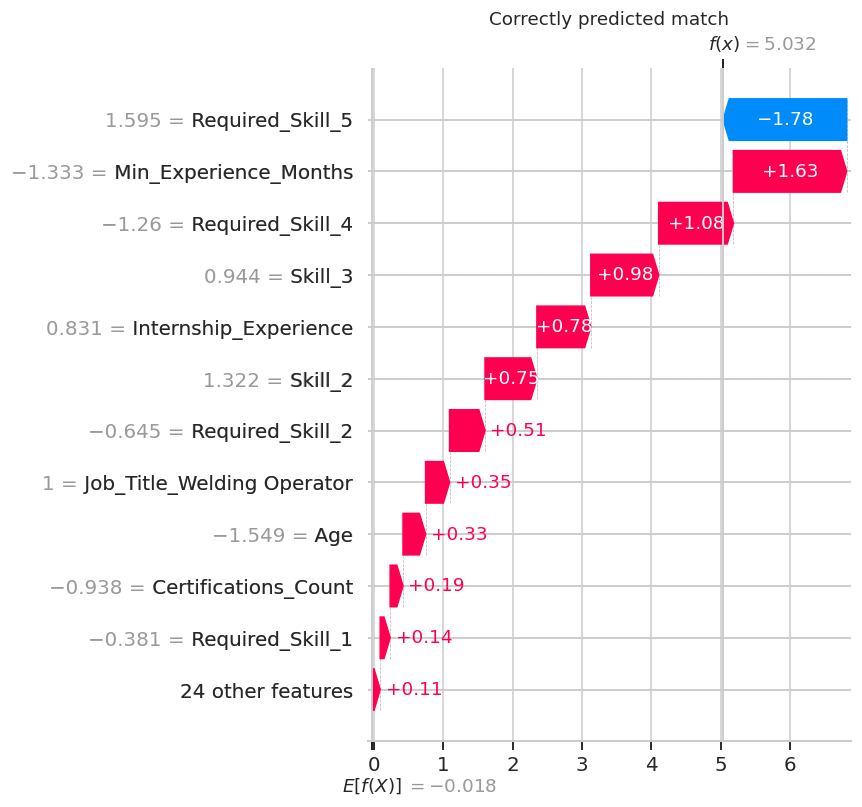

Correctly predicted non match: Student S1083, Internship 2 months against a requirement of 10 months


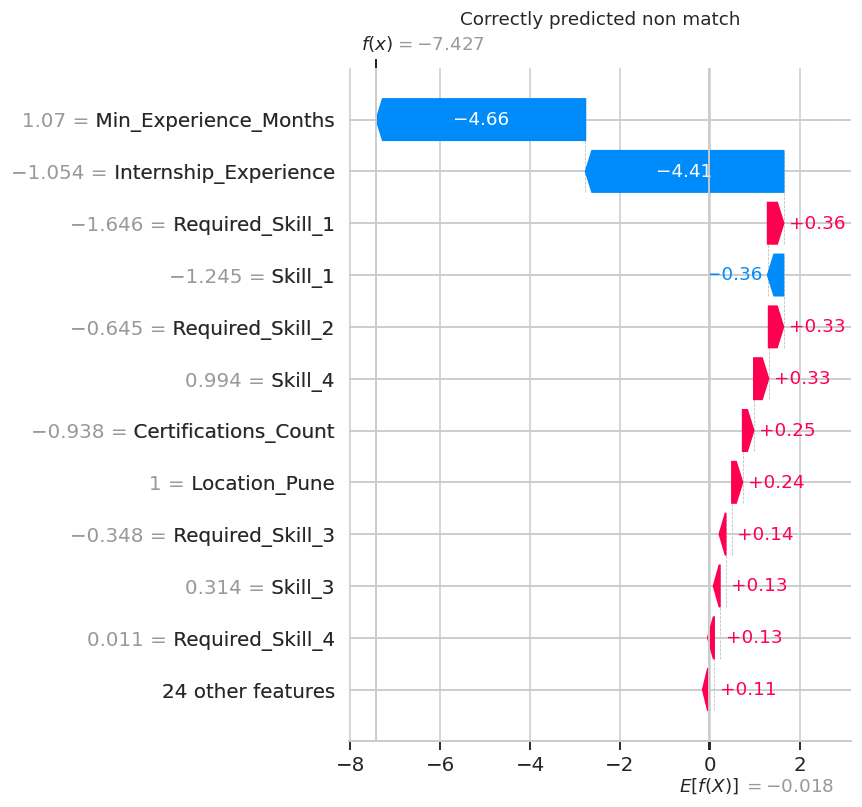

In [35]:
best_pred = predictions[best_name]
test_positions = np.arange(len(y_test))
true_match = test_positions[(y_test.values == 1) & (best_pred == 1)][0]
true_no_match = test_positions[(y_test.values == 0) & (best_pred == 0)][0]

for position, label, fname in [(true_match, 'Correctly predicted match', 'fig14_shap_local_match.png'),
                               (true_no_match, 'Correctly predicted non match', 'fig15_shap_local_no_match.png')]:
    record = X_test.iloc[position]
    print(f'{label}: Student {df.loc[X_test.index[position], "Student_ID"]}, '
          f'Internship {record["Internship_Experience"]} months against a requirement of '
          f'{record["Min_Experience_Months"]} months')
    shap.plots.waterfall(shap_explanation[position], max_display=12, show=False)
    plt.title(label)
    plt.tight_layout()
    plt.savefig(f'figures/{fname}', bbox_inches='tight')
    plt.show()

### What the Code Does

The code finds the first test record that is a correctly predicted match and the first that is a correctly predicted non match. For each, it prints the trainee's internship experience against the job's requirement and draws a SHAP waterfall plot. The plot starts at the model's average output, shown at the bottom as E[f(X)], and adds each feature's contribution in turn until it reaches the prediction for that trainee, shown at the top as f(x).

### Local Explanation Findings

Trainee S2398 had nine months of internship experience against a requirement of one month. The low experience requirement (+1.63) and a low Required_Skill_4 (+1.08) pushed most strongly towards a match, supported by high Skill_3 and Skill_2 scores and the trainee's own experience. One feature pushed against the match by 1.78: a high Required_Skill_5. The prediction still landed firmly on the match side, at 5.03 against an average close to zero.

Trainee S1083 had two months of internship experience against a requirement of ten months. Those two features alone pushed the prediction away from a match by 4.66 and 4.41. Several smaller features pushed back towards a match, but nowhere near enough to overcome the experience shortfall, and the prediction landed at 7.43 on the non match side.

This is the individual level explanation committed to in the proposal. A programme officer could see exactly why a specific trainee was or was not predicted to be matched, which is what makes the prediction open to examination and challenge (Lundberg and Lee, 2017).

### 9.5 How the Strongest Features Act Together

SHAP dependence plots show how one feature's SHAP value changes across its range. Here the actual (unscaled) internship experience is plotted against its SHAP value and coloured by the minimum experience the job requires, and the same is done in reverse. If the model has learned that experience matters relative to the requirement, the colours will separate clearly within each value.

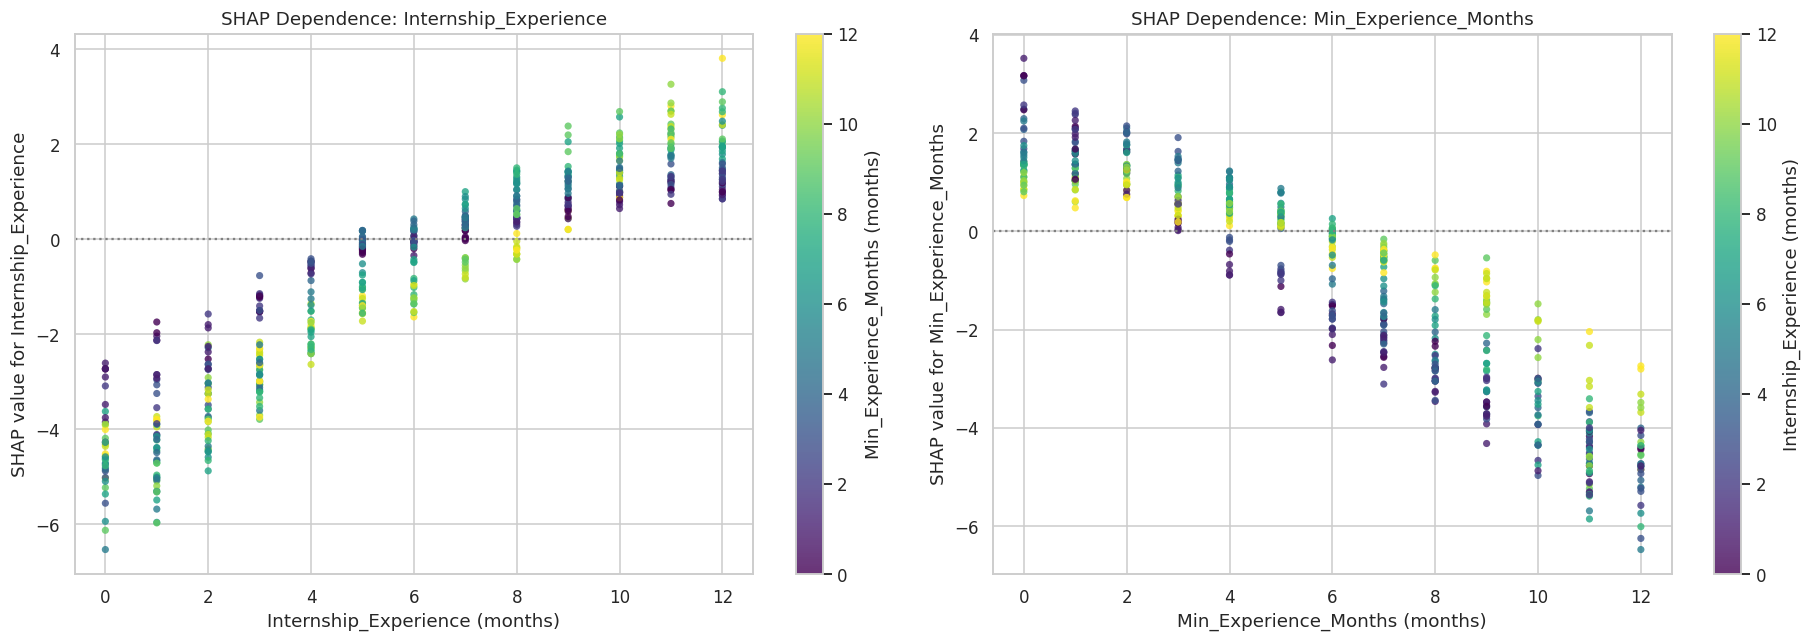

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
pairs = [('Internship_Experience', 'Min_Experience_Months'), ('Min_Experience_Months', 'Internship_Experience')]
for ax, (feature, colour_by) in zip(axes, pairs):
    idx = feature_names.index(feature)
    sc = ax.scatter(X_test[feature], shap_values[:, idx], c=X_test[colour_by], cmap='viridis',
                    s=22, alpha=0.8, edgecolor='none')
    ax.axhline(0, color='grey', linestyle='dotted')
    ax.set_xlabel(f'{feature} (months)')
    ax.set_ylabel(f'SHAP value for {feature}')
    ax.set_title(f'SHAP Dependence: {feature}')
    plt.colorbar(sc, ax=ax, label=f'{colour_by} (months)')
plt.tight_layout()
plt.savefig('figures/fig16_shap_dependence_experience.png', bbox_inches='tight')
plt.show()

### What the Code Does

For each of the two experience features, the code takes that feature's column of SHAP values and plots it against the original, unscaled values in months, colouring each point by the other experience feature.

### Dependence Findings

Internship_Experience has a steadily rising effect. Below about five months it pushes away from a match and above about six months it pushes towards one. Within each month, however, the points are spread vertically, and the colour shows why: at the same level of internship experience, records where the job required more experience (yellow) generally receive a lower SHAP value. The right hand panel shows the mirror image for the requirement.

The two features are therefore not acting independently. The model has partly learned that what matters is whether experience meets the requirement, an interaction that Section 11 confirms directly.

### 9.6 Hypothesis 1 Verdict

H1 stated that vocational skill assessment scores and prior internship experience would be the strongest predictors of post training employment outcomes. The rank of each training related field in the SHAP field ranking is shown below.

In [37]:
h1_fields = ['Internship_Experience'] + skill_cols + ['Certifications_Count', 'Academic_Performance', 'Vocational_Program']
h1_table = field_importance.set_index('Field').loc[h1_fields, ['Rank', 'Share of total (%)']].reset_index()
h1_table['Named in H1'] = h1_table['Field'].isin(['Internship_Experience'] + skill_cols).map({True: 'Yes', False: 'No'})
print(f'Total fields ranked: {len(field_importance)}')
h1_table

Total fields ranked: 19


,Field,Rank,Share of total (%),Named in H1
0,Internship_Experience,2,17.32,Yes
1,Skill_1,8,5.55,Yes
2,Skill_2,4,6.11,Yes
3,Skill_3,6,5.70,Yes
4,Skill_4,10,5.20,Yes
5,Skill_5,11,4.77,Yes
6,Certifications_Count,16,1.45,No
7,Academic_Performance,18,0.80,No
8,Vocational_Program,15,1.50,No


### What the Code Does

The code looks up the SHAP rank and share of importance for each training related field and marks which fields were named in H1.

### Hypothesis 1 Verdict

H1 predicted that vocational skill assessment scores and prior internship experience would be the strongest predictors of post training employment outcomes.

**H1 is partially supported.** Internship_Experience ranked second of nineteen fields, and the five skill scores ranked 4th, 6th, 8th, 10th and 11th. Every feature named in H1 sits in the top eleven, while the training measures not named in H1 ranked far lower (Vocational_Program 15th, Certifications_Count 16th and Academic_Performance 18th). The three feature selection methods in Section 6 point the same way.

The support is partial for two reasons. First, the single strongest predictor was not a training feature but Min_Experience_Months, which is a property of the job. Second, the skill scores did not predict on their own: each required skill level was about as important as the skill score it is compared with. The evidence supports a refined version of H1: skill scores and internship experience were the strongest training related predictors, but only in relation to the requirements of the job.

**Research link (RQ1, H1):** RQ1 is answered. The strongest training related predictors of employment were internship experience and the five skill assessment scores, read against the job's requirements. In Van Dijk's terms, second level skills translated into the third level outcome only where they met the level a particular job demanded.

## 10. Fairness Audit

The fairness audit checks whether the best model's predictions differ systematically across the two protected attributes in the dataset, gender and location. Following Zezulka and Genin (2024), it separates two questions: whether the model selects different groups at different rates, and whether it is equally accurate for each group. Four measures are calculated for each subgroup on the test set:

1. **Selection rate:** the share of the subgroup the model predicts will be matched.
2. **True positive rate:** of the subgroup members who were actually matched, the share the model found.
3. **False positive rate:** of the subgroup members who were not matched, the share the model wrongly predicted would be.
4. **F1 score** within the subgroup.

Two summary measures are then derived. The **disparate impact ratio** divides the lowest selection rate by the highest. A value below 0.8 is the conventional four fifths warning threshold. The **equal opportunity difference** is the gap between the highest and lowest true positive rate, where zero means perfect parity. Chi square tests check whether predicted outcomes and errors are statistically independent of each subgroup.

**Research link:** This section completes Objective 3, answers RQ3 and tests H3.

In [38]:
audit = X_test[['Gender', 'Location']].copy()
audit['actual'] = y_test.values
audit['predicted'] = predictions[best_name]
audit['error'] = (audit['actual'] != audit['predicted']).astype(int)

def subgroup_metrics(frame, attribute):
    rows = []
    for group, g in frame.groupby(attribute):
        tn, fp, fn, tp = confusion_matrix(g['actual'], g['predicted'], labels=[0, 1]).ravel()
        rows.append({
            'Attribute': attribute, 'Subgroup': group, 'Test records': len(g),
            'Actual match rate': g['actual'].mean(),
            'Selection rate': g['predicted'].mean(),
            'True positive rate': tp / (tp + fn) if (tp + fn) else np.nan,
            'False positive rate': fp / (fp + tn) if (fp + tn) else np.nan,
            'F1': f1_score(g['actual'], g['predicted'], zero_division=0),
            'Accuracy': accuracy_score(g['actual'], g['predicted'])
        })
    return pd.DataFrame(rows)

fairness_table = pd.concat([subgroup_metrics(audit, 'Gender'), subgroup_metrics(audit, 'Location')], ignore_index=True)
fairness_table.to_csv('results/table_fairness_subgroups.csv', index=False)
fairness_table.round(3)

,Attribute,Subgroup,Test records,Actual match rate,Selection rate,True positive rate,False positive rate,F1,Accuracy
0,Gender,Female,264,0.345,0.356,0.868,0.087,0.854,0.898
1,Gender,Male,298,0.292,0.315,0.851,0.095,0.818,0.889
2,Location,Bangalore,94,0.330,0.330,0.839,0.079,0.839,0.894
3,Location,Chennai,93,0.269,0.301,0.840,0.103,0.792,0.882
4,Location,Delhi,93,0.376,0.409,0.857,0.138,0.822,0.860
5,Location,Kolkata,90,0.367,0.367,0.909,0.053,0.909,0.933
6,Location,Mumbai,90,0.278,0.300,0.840,0.092,0.808,0.889
7,Location,Pune,102,0.284,0.304,0.862,0.082,0.833,0.902


### What the Code Does

The gender and location of each test record are combined with the actual outcomes and the XGBoost predictions. subgroup_metrics then loops over each subgroup, builds its confusion matrix, and calculates its actual match rate, selection rate, true positive rate, false positive rate, F1 and accuracy.

### Subgroup Findings

For gender, the model selected 35.6 percent of female trainees and 31.5 percent of male trainees as matches, closely tracking the actual match rates in the test set (34.5 and 29.2 percent). True positive rates were nearly equal (0.868 for female and 0.851 for male trainees), as were false positive rates (0.087 and 0.095).

For location, selection rates ranged from 30.0 percent in Mumbai to 40.9 percent in Delhi, again following the actual match rates (27.8 to 37.6 percent). True positive rates ranged from 0.839 in Bangalore to 0.909 in Kolkata. Delhi had the highest false positive rate (0.138) and Kolkata the lowest (0.053). Each city has only 90 to 102 test records, so results for individual cities rest on small numbers.

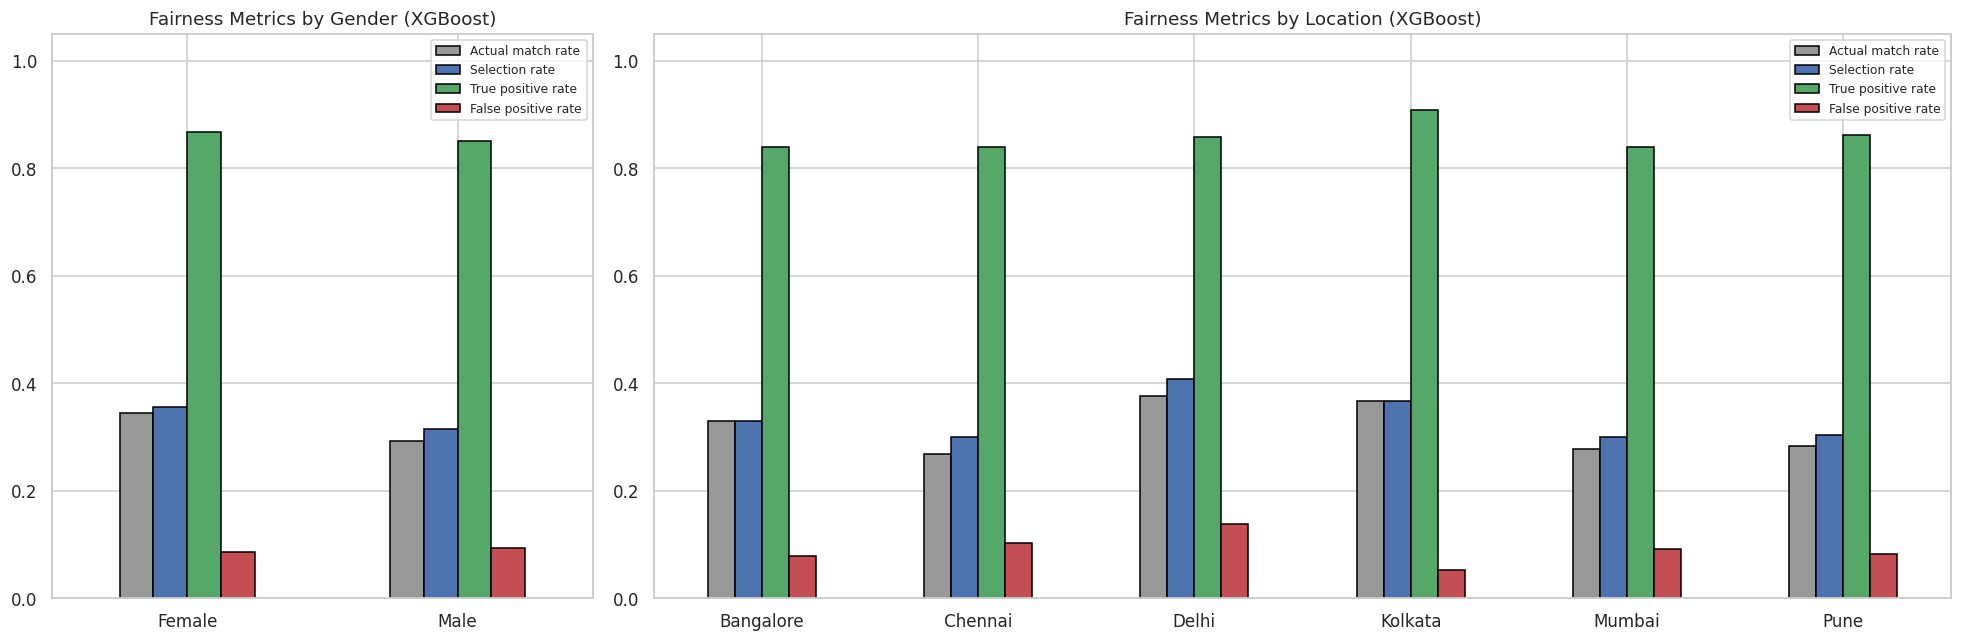

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6), gridspec_kw={'width_ratios': [1, 2.4]})
for ax, attribute in zip(axes, ['Gender', 'Location']):
    sub = fairness_table[fairness_table['Attribute'] == attribute].set_index('Subgroup')
    sub[['Actual match rate', 'Selection rate', 'True positive rate', 'False positive rate']].plot(
        kind='bar', ax=ax, edgecolor='black', color=['#999999', '#4C72B0', '#55A868', '#C44E52'])
    ax.set_title(f'Fairness Metrics by {attribute} ({best_name})')
    ax.set_ylim(0, 1.05)
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=0)
    ax.legend(fontsize=8, loc='upper right')
plt.tight_layout()
plt.savefig('figures/fig17_fairness_by_subgroup.png', bbox_inches='tight')
plt.show()

### What the Code Does

For each attribute, the four rates are drawn as grouped bars for every subgroup.

### Fairness Chart Findings

In every subgroup the selection rate bar sits close to the actual match rate bar, so the model is not systematically over selecting or under selecting any group relative to how often that group was actually matched. True positive rates are similar across all subgroups.

### 10.1 Summary Fairness Measures and Statistical Tests

In [40]:
summary_rows = []
for attribute in ['Gender', 'Location']:
    sub = fairness_table[fairness_table['Attribute'] == attribute]
    # chi square tests of independence between the subgroup and the predicted outcome, actual outcome and errors
    p_pred = stats.chi2_contingency(pd.crosstab(audit[attribute], audit['predicted']))[1]
    p_actual = stats.chi2_contingency(pd.crosstab(audit[attribute], audit['actual']))[1]
    p_error = stats.chi2_contingency(pd.crosstab(audit[attribute], audit['error']))[1]
    # share of total SHAP importance carried by the attribute's own one hot columns
    shap_share = field_importance.set_index('Field').loc[attribute, 'Share of total (%)']
    summary_rows.append({
        'Attribute': attribute,
        'Disparate impact ratio': sub['Selection rate'].min() / sub['Selection rate'].max(),
        'Equal opportunity difference': sub['True positive rate'].max() - sub['True positive rate'].min(),
        'p value: prediction vs subgroup': p_pred,
        'p value: actual outcome vs subgroup': p_actual,
        'p value: error vs subgroup': p_error,
        'SHAP share of attribute (%)': shap_share
    })
fairness_summary = pd.DataFrame(summary_rows)
fairness_summary.to_csv('results/table_fairness_summary.csv', index=False)
fairness_summary.round(4)

,Attribute,Disparate impact ratio,Equal opportunity difference,p value: prediction vs subgroup,p value: actual outcome vs subgroup,p value: error vs subgroup,SHAP share of attribute (%)
0,Gender,0.8859,0.0176,0.3528,0.211,0.8513,1.08
1,Location,0.7342,0.0704,0.5354,0.447,0.7293,1.72


### What the Code Does

For each attribute, the code calculates the disparate impact ratio and the equal opportunity difference, runs chi square tests of whether the predictions, the actual outcomes and the errors depend on the subgroup, and looks up the attribute's share of SHAP importance from Section 9.3.

### Fairness Summary Findings

For gender, the disparate impact ratio was 0.886, above the 0.8 threshold, and the equal opportunity difference was 0.018. The predicted outcome was independent of gender (p = 0.353), and so were the errors (p = 0.851).

For location, the disparate impact ratio was 0.734, below the 0.8 threshold. On its own this would be a warning sign. Three further results show that it reflects differences within the test sample rather than bias in the model:

1. The actual match rates differed between cities by a similar amount (27 to 38 percent), and that difference was itself not statistically significant (p = 0.447), which is consistent with sampling variation in small subgroups.
2. The predictions were independent of location (p = 0.535).
3. The errors were independent of location (p = 0.729), so the model was no more likely to be wrong for one city than for another.

SHAP shows the same picture from inside the model: gender carried 1.08 percent and location 1.72 percent of total importance. Neither share is zero, and that matters. Section 11 shows that neither attribute has any effect on the true outcome, so even this small share is noise that the model learned from the training data.

### 10.2 Fairness Across All Five Models

To check that the result is not specific to the best model, the same two summary measures are calculated for every model.

In [41]:
all_model_rows = []
for name in results['Model']:
    frame = X_test[['Gender', 'Location']].copy()
    frame['actual'] = y_test.values
    frame['predicted'] = predictions[name]
    for attribute in ['Gender', 'Location']:
        sub = subgroup_metrics(frame, attribute)
        all_model_rows.append({
            'Model': name, 'Attribute': attribute,
            'Disparate impact ratio': sub['Selection rate'].min() / sub['Selection rate'].max(),
            'Equal opportunity difference': sub['True positive rate'].max() - sub['True positive rate'].min(),
            'p value: prediction vs subgroup': stats.chi2_contingency(pd.crosstab(frame[attribute], frame['predicted']))[1]
        })
fairness_all_models = pd.DataFrame(all_model_rows)
fairness_all_models.to_csv('results/table_fairness_all_models.csv', index=False)
fairness_all_models.round(4)

,Model,Attribute,Disparate impact ratio,Equal opportunity difference,p value: prediction vs subgroup
0,XGBoost,Gender,0.8859,0.0176,0.3528
1,XGBoost,Location,0.7342,0.0704,0.5354
2,Support Vector Machine,Gender,0.8333,0.0990,0.1350
3,Support Vector Machine,Location,0.7290,0.1703,0.6910
4,Random Forest,Gender,0.8640,0.0471,0.3173
5,Random Forest,Location,0.7000,0.1842,0.6637
6,Logistic Regression,Gender,0.8859,0.0296,0.2747
7,Logistic Regression,Location,0.8783,0.0800,0.9823
8,Decision Tree,Gender,0.9662,0.1138,0.8116
9,Decision Tree,Location,0.8006,0.1685,0.6706


### What the Code Does

The same two summary measures and the chi square test on predictions are calculated for the test predictions of every model.

### All Model Findings

No model's predictions depended significantly on gender or location: every p value was above 0.13. Disparate impact ratios for location fell below 0.8 for XGBoost (0.734), the support vector machine (0.729) and random forest (0.700), and sat just above it for the decision tree (0.801) and logistic regression (0.878). Equal opportunity differences for location ranged from 0.070 for XGBoost to 0.184 for random forest, and for gender XGBoost also had the smallest difference (0.018). XGBoost therefore had the most even true positive rates across subgroups of any model.

### Hypothesis 3 Verdict

H3 predicted that significant differences in prediction outcomes would exist across demographic subgroups based on gender and geographic location, revealed by SHAP.

**H3 is not supported.** No significant difference in predictions was found for gender (p = 0.353) or location (p = 0.535), the errors did not depend on either attribute, and SHAP assigned gender and location only 1.08 and 1.72 percent of the model's reasoning. The location disparate impact ratio of 0.734 fell below the conventional threshold, but the evidence in Section 10.1 attributes it to differences in actual match rates within a small test sample rather than to the model.

This result needs to be read carefully. The model was fair here because the outcome it learned from does not depend on gender or location. That is not evidence that the pipeline would produce fair predictions on real labour market data, where historical discrimination can be built into the outcome itself (Pasipamire and Muroyiwa, 2024). What the audit does show is that the pipeline can detect and measure disparity, and that it can tell apart a disparity driven by base rates from one driven by the model, as Zezulka and Genin (2024) recommend.

**Research link (O3, RQ3, H3):** Objective 3 is complete. RQ3 is answered: the best model's predictions did not differ systematically across gender or location, and SHAP showed that both attributes contributed very little to the model's decisions. The ethical implication is taken up in the Discussion: an audit that finds no bias is only as reassuring as the data it was run on.

## 11. Ground Truth Validation and Sensitivity Analysis

This section goes beyond the analysis plan in the proposal. It was added after the exploratory analysis and the SHAP results pointed to a very specific pattern: the outcome appeared to depend not on skill or experience levels on their own, but on whether they met the levels each job required. Because the dataset is synthetic, its outcome may have been generated by a fixed rule. If such a rule exists it provides a known ground truth, which allows a check that is rarely possible with real data: did SHAP identify the features that truly determine the outcome?

This section is exploratory. It does not change the hypothesis verdicts above, which rest on the approved pipeline.

### 11.1 Testing for a Deterministic Rule

Two comparison features are created for every record: the number of the five skills on which the trainee meets or exceeds the job's requirement, and whether the trainee's internship experience meets the job's minimum experience requirement. These are compared directly against Job_Match.

In [42]:
rule_df = df.copy()

# for each of the five skills, does the trainee meet or exceed the job requirement
for i in range(1, 6):
    rule_df[f'Meets_Skill_{i}'] = (rule_df[f'Skill_{i}'] >= rule_df[f'Required_Skill_{i}']).astype(int)
rule_df['Skills_Met'] = rule_df[[f'Meets_Skill_{i}' for i in range(1, 6)]].sum(axis=1)

# does the trainee's internship experience meet the minimum the job requires
rule_df['Meets_Experience'] = (rule_df['Internship_Experience'] >= rule_df['Min_Experience_Months']).astype(int)

# match rate for every combination of skills met and experience met
rule_table = pd.crosstab([rule_df['Skills_Met'], rule_df['Meets_Experience']], rule_df['Job_Match'],
                         margins=True, margins_name='Total')
rule_table.columns = ['No match (0)', 'Match (1)', 'Total']
rule_table

No match (0)  Match (1)  Total
Skills_Met Meets_Experience                                
0          0                           35          0     35
           1                           31          0     31
1          0                          160          0    160
           1                          187          0    187
2          0                          388          0    388
           1                          414          0    414
3          0                          415          0    415
           1                            0        535    535
4          0                          242          0    242
           1                            0        289    289
5          0                           46          0     46
           1                            0         67     67
Total                                1918        891   2809

### What the Code Does

Five indicator columns record whether the trainee meets each of the five skill requirements, and Skills_Met adds them up to give a count from zero to five. Meets_Experience records whether internship experience reaches the job's minimum. pd.crosstab then counts the outcomes for every combination of the two.

### Rule Table Findings

The table shows a sharp pattern with no exceptions. Every record that meets fewer than three skill requirements is a non match, whatever its experience. Every record that fails the experience requirement is a non match, whatever its skills. Every one of the 891 records that meets at least three skill requirements and the experience requirement is a match.

In [43]:
# the candidate rule: at least three of five skills met AND experience requirement met
rule_df['Rule_Prediction'] = ((rule_df['Skills_Met'] >= 3) & (rule_df['Meets_Experience'] == 1)).astype(int)
agreement = (rule_df['Rule_Prediction'] == rule_df['Job_Match']).mean()

print('Candidate rule: Job_Match = 1 if Skills_Met >= 3 and Meets_Experience = 1, otherwise 0')
print(f'Agreement with Job_Match across all {len(rule_df)} records: {agreement * 100:.2f} percent')
print(f'Records where the rule and Job_Match disagree: {(rule_df["Rule_Prediction"] != rule_df["Job_Match"]).sum()}')
print()
print(confusion_matrix(rule_df['Job_Match'], rule_df['Rule_Prediction']))

Candidate rule: Job_Match = 1 if Skills_Met >= 3 and Meets_Experience = 1, otherwise 0
Agreement with Job_Match across all 2809 records: 100.00 percent
Records where the rule and Job_Match disagree: 0

[[1918    0]
 [   0  891]]


### What the Code Does

The candidate rule is written as a single condition, applied to every record, and compared with Job_Match.

### Rule Agreement Findings

The rule agrees with Job_Match on all 2,809 records, with no disagreements. The outcome in this dataset is therefore fully determined by a simple rule: a trainee is matched if and only if they meet at least three of the job's five skill requirements and their internship experience meets the job's minimum. Gender, location, age, vocational programme, academic performance and certifications play no part.

This confirms that the dataset is synthetic, as stated in the proposal. Real employment outcomes are never determined by a rule this exact.

### 11.2 Did SHAP Recover the True Drivers?

If the rule above generates the outcome, then exactly twelve fields matter (the five skill scores, the five required skill levels, internship experience and minimum experience) and the remaining seven fields have no true effect. The cell below measures how much of the best model's SHAP importance fell on the twelve rule fields.

In [44]:
rule_fields = skill_cols + req_cols + ['Internship_Experience', 'Min_Experience_Months']
field_importance['In true rule'] = field_importance['Field'].isin(rule_fields).map({True: 'Yes', False: 'No'})

share_rule = field_importance.loc[field_importance['In true rule'] == 'Yes', 'Share of total (%)'].sum()
top12 = set(field_importance.head(12)['Field'])
overlap = len(top12 & set(rule_fields))

print(f'Share of SHAP importance on the 12 rule fields:      {share_rule:.2f} percent')
share_non_rule = 100 - share_rule
print(f'Share of SHAP importance on the 7 non rule fields:   {share_non_rule:.2f} percent')
print(f'Rule fields among the 12 highest ranked SHAP fields:  {overlap} of 12')
field_importance[['Rank', 'Field', 'In true rule', 'Share of total (%)']]

Share of SHAP importance on the 12 rule fields:      90.09 percent
Share of SHAP importance on the 7 non rule fields:   9.91 percent
Rule fields among the 12 highest ranked SHAP fields:  12 of 12


,Rank,Field,In true rule,Share of total (%)
0,1,Min_Experience_Months,Yes,17.51
1,2,Internship_Experience,Yes,17.32
2,3,Required_Skill_3,Yes,6.56
3,4,Skill_2,Yes,6.11
4,5,Required_Skill_5,Yes,5.86
5,6,Skill_3,Yes,5.70
6,7,Required_Skill_4,Yes,5.67
7,8,Skill_1,Yes,5.55
8,9,Required_Skill_2,Yes,5.43
9,10,Skill_4,Yes,5.20


### What the Code Does

Each field is flagged according to whether it appears in the rule. The code then calculates the share of total SHAP importance that fell on those fields and how many of them appear in the top twelve of the SHAP ranking.

### SHAP Validation Findings

SHAP placed 90.09 percent of the model's importance on the twelve fields that actually determine the outcome, and the top twelve positions in the SHAP ranking are exactly those twelve fields. Every field outside the rule ranked below every field inside it.

This is the most important methodological result of the study. Studies using real data cannot check whether SHAP has identified the true drivers of an outcome, because the true drivers are unknown. Here they are known, and SHAP recovered all of them without being told what they were. The remaining 9.91 percent, spread across seven fields that have no true effect, is a measure of how much noise the model absorbed from a training set of 2,247 records.

### 11.3 Sensitivity Analysis with Comparison Features

The raw features describe the trainee and the job separately, while the rule depends on the comparison between them. To test whether the gap between the models in Section 8 comes from this representation rather than from a lack of signal, the five models are retrained with exactly the same pipeline and tuned hyperparameters, but with comparison features added: the gap between each skill and its requirement, the number of skills met, and the gap between internship experience and the experience requirement.

In [45]:
def add_comparison_features(frame):
    out = frame.copy()
    for i in range(1, 6):
        out[f'Skill_Gap_{i}'] = out[f'Skill_{i}'] - out[f'Required_Skill_{i}']
    out['Skills_Met'] = (out[[f'Skill_Gap_{i}' for i in range(1, 6)]] >= 0).sum(axis=1)
    out['Experience_Gap'] = out['Internship_Experience'] - out['Min_Experience_Months']
    return out

X_train_eng = add_comparison_features(X_train)
X_test_eng = add_comparison_features(X_test)
numerical_eng = [c for c in X_train_eng.columns if c not in categorical_cols]

preprocessor_eng = ColumnTransformer(transformers=[
    ('numerical', StandardScaler(), numerical_eng),
    ('categorical', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols)
])

sensitivity_rows = []
for name, tuned in best_models.items():
    # reuse the tuned hyperparameters from Section 7 so only the features change
    model = clone(tuned.named_steps['model'])
    pipeline = ImbPipeline(steps=[('preprocess', preprocessor_eng),
                                  ('smote', SMOTE(random_state=RANDOM_STATE)),
                                  ('model', model)])
    pipeline.fit(X_train_eng, y_train)
    metrics = evaluate(pipeline, X_test_eng, y_test)
    original = results.set_index('Model').loc[name]
    sensitivity_rows.append({'Model': name,
                             'F1 (raw features)': original['F1'], 'F1 (with comparison features)': metrics['F1'],
                             'MCC (raw features)': original['MCC'], 'MCC (with comparison features)': metrics['MCC']})
sensitivity = pd.DataFrame(sensitivity_rows)
sensitivity.to_csv('results/table_sensitivity_analysis.csv', index=False)
sensitivity.round(4)

,Model,F1 (raw features),F1 (with comparison features),MCC (raw features),MCC (with comparison features)
0,Logistic Regression,0.7426,0.8150,0.6117,0.7252
1,Decision Tree,0.7003,1.0000,0.5462,1.0000
2,Random Forest,0.7396,1.0000,0.6300,1.0000
3,XGBoost,0.8361,1.0000,0.7576,1.0000
4,Support Vector Machine,0.7594,0.9176,0.6414,0.8786


### What the Code Does

add_comparison_features adds seven new columns to a copy of the data: the gap between each skill and its requirement, the number of skills met, and the gap between internship experience and the experience requirement. A new preprocessor handles the larger feature set. Each model is rebuilt with the hyperparameters chosen in Section 7, trained on the training set and scored on the test set.

### Sensitivity Findings

With the comparison features added, the decision tree, random forest and XGBoost all reached a perfect F1 and MCC of 1.000 on the test set. The support vector machine improved from an MCC of 0.641 to 0.879 and logistic regression from 0.612 to 0.725. The linear model remains limited because the rule is a combination of thresholds, which a single linear boundary cannot represent exactly.

The models in Section 8 were therefore not held back by a lack of information in the data. They were held back by how the data was represented: the raw features describe the trainee and the job separately, while the outcome depends on the comparison between them. Tree models can learn such a comparison only approximately, by building many splits, and XGBoost did so most efficiently, which is consistent with its lead in Section 8.

This has a practical implication for future work with real data. Features that describe the fit between a trainee and a specific job, rather than the trainee alone, may be far more predictive than the trainee attributes that most programme evaluations record.

## 12. Results Against the Research Questions, Hypotheses and Objectives

The table below brings together the evidence from every section and records the verdict for each hypothesis and the status of each objective.

In [46]:
best_row = results.loc[0]
lr = results.set_index('Model').loc['Logistic Regression']
gender_sum = fairness_summary.set_index('Attribute').loc['Gender']
location_sum = fairness_summary.set_index('Attribute').loc['Location']

summary = pd.DataFrame([
    {'Item': 'RQ1 / H1 / O1',
     'Key evidence': (f"Top SHAP fields: {', '.join(field_importance.head(4)['Field'])}. "
                      f"Internship_Experience ranked {int(field_importance.set_index('Field').loc['Internship_Experience','Rank'])}; "
                      f"Certifications_Count ranked {int(field_importance.set_index('Field').loc['Certifications_Count','Rank'])} and "
                      f"Academic_Performance ranked {int(field_importance.set_index('Field').loc['Academic_Performance','Rank'])} of {len(field_importance)}."),
     'Verdict': 'H1 partially supported'},
    {'Item': 'RQ2 / H2 / O2',
     'Key evidence': (f"Best model {best_row['Model']}: F1 {best_row['F1']:.3f}, MCC {best_row['MCC']:.3f}. "
                      f"Logistic regression: F1 {lr['F1']:.3f}, MCC {lr['MCC']:.3f}."),
     'Verdict': 'See Section 8.7'},
    {'Item': 'RQ3 / H3 / O3',
     'Key evidence': (f"Gender: disparate impact {gender_sum['Disparate impact ratio']:.3f}, p = {gender_sum['p value: prediction vs subgroup']:.3f}. "
                      f"Location: disparate impact {location_sum['Disparate impact ratio']:.3f}, p = {location_sum['p value: prediction vs subgroup']:.3f}."),
     'Verdict': 'See Section 10'},
])
pd.set_option('display.max_colwidth', None)
summary

,Item,Key evidence,Verdict
0,RQ1 / H1 / O1,"Top SHAP fields: Min_Experience_Months, Internship_Experience, Required_Skill_3, Skill_2. Internship_Experience ranked 2; Certifications_Count ranked 16 and Academic_Performance ranked 18 of 19.",H1 partially supported
1,RQ2 / H2 / O2,"Best model XGBoost: F1 0.836, MCC 0.758. Logistic regression: F1 0.743, MCC 0.612.",See Section 8.7
2,RQ3 / H3 / O3,"Gender: disparate impact 0.886, p = 0.353. Location: disparate impact 0.734, p = 0.535.",See Section 10


### What the Code Does

The code gathers the key result for each research question from the earlier sections into a single table, building each line from the stored results so that the figures always match the outputs above.



### End of Analysis